<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">هفتهٔ ۱۱ | رگرسیون خطی و چندجمله‌ای </strong><div><p>این نوت‌بوک شامل <strong>چهار بخش آموزشی</strong> است: رگرسیون خطی و هزینه، گرادیان کاهشی، مدل چندمتغیره و ارزیابی، و رگرسیون چندجمله‌ای. فرمول‌ها، نکات علمی و مثال‌های تصویری در متن آمده‌اند و بعضی بخش‌های برنامه‌نویسی را خودتان تکمیل می‌کنید.</p><p>هرجا <code>TODO</code> و <code>...</code> می‌بینید، باید عبارت مناسب پایتون را جایگزین کنید. <strong>پیش از تکمیل تمرین‌ها، اجرای کامل Notebook ممکن است خطا بدهد و این طبیعی است.</strong> از بالا به پایین پیش بروید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">کتابخانه‌ها و آماده‌سازی</strong><div><p>در سلول بعدی ابزارهای NumPy، Pandas، Matplotlib و Scikit-Learn را وارد می‌کنیم، مقدار ثابت تصادفی تعیین می‌کنیم و مسیر فایل‌های داده را مشخص می‌کنیم.</p></div></div>

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)

# Read both datasets from the data folder next to this notebook.
DATA_DIR = Path("data")
assert (DATA_DIR / "california_housing.csv").exists(), "Dataset CSV not found; extract the complete ZIP first."
assert (DATA_DIR / "polynomial_dataset.csv").exists(), "Polynomial dataset CSV not found; extract the complete ZIP first."
print("Dataset directory:", DATA_DIR.resolve())
print("NumPy version:", np.__version__)

Dataset directory: C:\Users\NoteBook\Desktop\Week11_Linear_Regression_Student_Boxed_Package\Week11_Linear_Regression_Student\data
NumPy version: 2.2.6


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">دستورهای اصلی سلول آماده‌سازی</strong><div><p><code>Path</code> برای ساخت مسیر فایل، <code>numpy as np</code> برای عملیات آرایه‌ای، <code>pandas as pd</code> برای جدول و <code>matplotlib.pyplot as plt</code> برای رسم نمودار است. <code>train_test_split</code> داده را به Train/Test تقسیم می‌کند. <code>LinearRegression</code> و <code>DummyRegressor</code> دو مدل مورد استفاده‌اند و تابع‌های <code>metrics</code> برای اندازه‌گیری خطا هستند.</p><p>مقدار <code>SEED</code> ثابت می‌ماند تا بخش‌های تصادفی تا حد امکان قابل تکرار باشند. وجود فایل CSV را قبل از خواندن بررسی می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">بخش ۱ | آشنایی با رگرسیون خطی و ریاضیات خطا</strong><div><p>رگرسیون در برابر طبقه‌بندی، مدل خطی، باقی‌مانده، MSE، روش کمترین مربعات و مشتق تابع هزینه. در پایان این بخش یک مرحله از Gradient Descent را بررسی می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | رگرسیون یا طبقه‌بندی؟</strong><div><p>از یک سؤال واقعی شروع می‌کنیم: خروجی مدل «عدد» است یا «برچسب»؟ بعد نماد x و y را تعریف می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مسئلهٔ رگرسیون چیست؟</strong><div><p>در <strong>Regression</strong> پاسخ، یک کمیت عددی است؛ مثل قیمت، دما یا زمان. در <strong>Classification</strong> پاسخ یک برچسب است؛ مثل «قبول/رد». اینکه برچسب با عدد ۰ و ۱ نمایش داده شود، آن را خودبه‌خود رگرسیون نمی‌کند: نوع سؤال و معنای خروجی مهم است.</p>
<p><strong>مثال:</strong> ورودی «تعداد ساعت مطالعه» و خروجی «نمرهٔ امتحان» یک تقریب آموزشی است. از این رابطه نمی‌توان به‌تنهایی نتیجه گرفت افزایش ساعت مطالعه <strong>علت قطعی</strong> افزایش نمره است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | مدل خطی ساده</strong><div><p>در این بخش، معنی ورودی، مشاهدهٔ واقعی، پیش‌بینی، شیب و بایاس را با مثال ساعت مطالعه مشخص می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">از داده به نمادها: x ،y و ŷ</strong><div><p>برای هر مشاهده، یک مقدار ورودی <code>x</code> (ساعت مطالعه) و یک مقدار مشاهده‌شده <code>y</code> (نمره) داریم. مجموعهٔ این زوج‌ها را دادهٔ آموزشی می‌نامیم. <code>ŷ</code> یا «وای کلاه‌دار» <strong>پیش‌بینی مدل</strong> است، نه جواب واقعی. در دفتر جدول سه‌ستونی <code>x</code>، <code>y</code> و <code>ŷ</code> بکشید؛ ستون سوم را تا زمان انتخاب مدل خالی می‌ماند.</p></div></div>

### مدل رگرسیون خطی ساده

$$
\hat y = wx+b
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خواندن جزءبه‌جزء فرمول</strong><div><ul>
<li><code>x</code> ورودی است و <code>ŷ</code> خروجی پیش‌بینی‌شده.</li>
<li><code>w</code> <strong>وزن یا شیب (slope)</strong>: اگر <code>x</code> یک واحد بیشتر شود و سایر شرایط یکسان باشند، پیش‌بینی <code>w</code> واحد تغییر می‌کند.</li>
<li><code>b</code> <strong>بایاس یا عرض از مبدأ (intercept)</strong>: پیش‌بینی در <code>x=0</code>؛ لزوماً تفسیر واقعی ندارد اگر صفر بیرون محدودهٔ داده باشد.</li>
<li><strong>پارامتر</strong> یعنی عددی که از داده یاد می‌گیریم (<code>w</code> و <code>b</code>)؛ <strong>ابرپارامتر</strong> مثل نرخ یادگیری را پیش از آموزش تعیین می‌کنیم.</li>
</ul>
<p>با <code>w=7</code> و <code>b=20</code>، برای <code>x=4</code> داریم <code>ŷ=48</code>. واحد <code>w</code> در این مثال «امتیاز نمره به ازای هر ساعت» است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | نقاط واقعی و نمودار</strong><div><p>این قسمت نمودار پراکنش می‌سازد تا تفاوت مشاهدهٔ واقعی با خط حدسی را بصری ببینیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

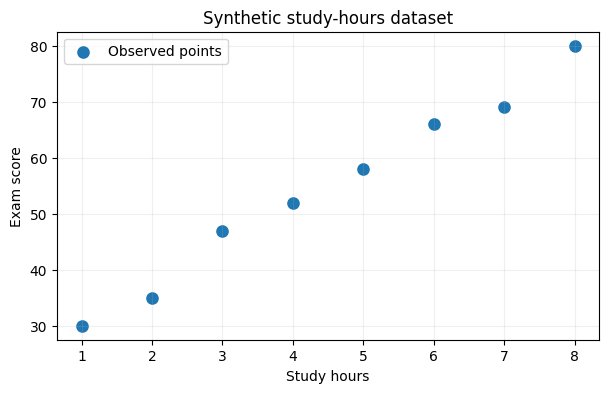

Number of observations: 8
Shapes: (8,) (8,)


In [2]:
# Make a small synthetic dataset with eight paired observations.
hours = np.arange(1, 9, dtype=float)
scores = np.array([30, 35, 47, 52, 58, 66, 69, 80], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(hours, scores, s=65, label="Observed points")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Synthetic study-hours dataset")
plt.grid(alpha=0.2)
plt.legend()
plt.show()
print("Number of observations:", len(hours))
print("Shapes:", hours.shape, scores.shape)

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جزئیات کدِ ساخت داده و نمودار</strong><div><ul>
<li><code>np.arange(1, 9, dtype=float)</code> عددهای ۱ تا <strong>۸</strong> را تولید می‌کند؛ انتهای بازه یعنی ۹ شامل نمی‌شود.</li>
<li><code>np.array([...], dtype=float)</code> فهرست را به آرایهٔ عددی تبدیل می‌کند. نگه‌داشتن ترتیب دو آرایه حیاتی است.</li>
<li><code>plt.figure(figsize=(7, 4))</code> اندازهٔ شکل را تعیین می‌کند.</li>
<li><code>plt.scatter(hours, scores)</code> به ازای هر جفتِ هم‌اندیس یک نقطه رسم می‌کند؛ <code>s=65</code> اندازهٔ نشانگر و <code>label</code> اسم راهنمای نمودار است.</li>
<li><code>xlabel</code> و <code>ylabel</code> نام و واحدِ دو محور؛ <code>grid(alpha=0.2)</code> شبکهٔ کم‌رنگ؛ <code>show()</code> نمایش نتیجه.</li>
<li><code>.shape</code> در اینجا <code>(8,)</code> است: یک آرایهٔ یک‌بعدی با هشت عضو، نه یک ماتریس ۸×۱.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | پیش‌بینی دستی</strong><div><p>فعلاً مدل آموزش‌ندیده است؛ دو پارامتر را حدس می‌زنیم و با همان‌ها خروجی را برای چند x می‌سازیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱ | پیش‌بینی از روی خط</strong><div><p>در سلول بعد با همان <code>w_try</code>، <code>b_try</code> و آرایهٔ <code>hours</code> بردار پیش‌بینی‌ها را با استفاده از محاسبات برداری NumPy بسازید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

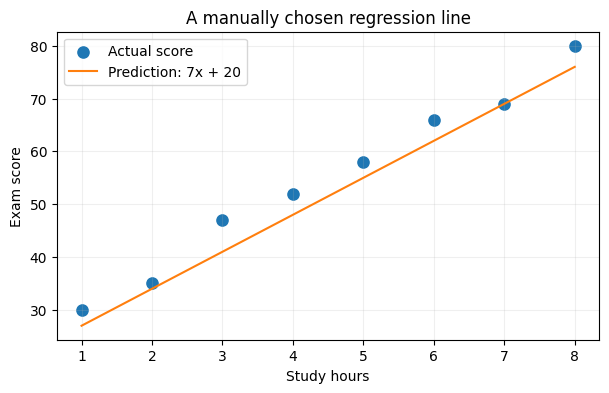

Predicted scores: [27. 34. 41. 48. 55. 62. 69. 76.]
Prediction for 5 hours: 55.0


In [3]:
# Choose parameters manually; the model has not been trained yet.
w_try = 7.0
b_try = 20.0
pred_try =  w_try *  hours + b_try # TODO 01: Predict every score using w_try, hours, and b_try.

plt.figure(figsize=(7, 4))
plt.scatter(hours, scores, s=65, label="Actual score")
plt.plot(hours, pred_try, color="tab:orange", label="Prediction: 7x + 20")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("A manually chosen regression line")
plt.grid(alpha=0.2)
plt.legend()
plt.show()
print("Predicted scores:", pred_try)
print("Prediction for 5 hours:", w_try * 5 + b_try)

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا ضرب یک عدد در آرایه کار می‌کند؟</strong><div><p><code>w_try * hours</code> در NumPy هر هشت عدد آرایه را جداگانه در ۷ ضرب می‌کند؛ <code>+b_try</code> نیز ۲۰ را به هر هشت نتیجه می‌افزاید. در اینجا <code>pred_try</code> یک آرایهٔ هشت‌تایی است. <code>plt.plot</code> نقاط پیش‌بینی‌شده را به شکل خط به هم وصل می‌کند. تفاوت <code>plot</code> (خط) و <code>scatter</code> (نقطه) را روی شکل مشخص کنید. <code>w_try</code> و <code>b_try</code> هنوز <strong>پارامترهای حدسی</strong>‌اند، نه خروجی <code>fit</code>.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | باقی‌مانده و معیار خطا</strong><div><p>پیش‌بینی‌ها کامل نیستند؛ در چند سلول بعدی خطا را برای هر سطر حساب و MAE/MSE را مقایسه می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خطا باید برای هر نمونه جداگانه تعریف شود</strong><div><p>در این نوت‌بوک قرارداد <strong>باقی‌مانده</strong> را <code>r_i = ŷ_i − y_i</code> می‌گیریم؛ بعضی کتاب‌ها <code>y_i − ŷ_i</code> را می‌نامند. هر دو قرارداد درست‌اند، به شرط سازگاری. مقدار مثبت در قرارداد ما یعنی بیش‌برآورد، مقدار منفی یعنی کم‌برآورد. میانگین سادهٔ باقی‌مانده‌ها معیار خوبی نیست، چون خطاهای مثبت و منفی می‌توانند همدیگر را خنثی کنند.</p></div></div>

### تعریف خطا، MAE و MSE

$$
\begin{aligned}r_i&=\hat y_i-y_i\\ \mathrm{MAE}&=\frac{1}{m}\sum_{i=1}^{m}|r_i|\\ \mathrm{MSE}&=\frac{1}{m}\sum_{i=1}^{m}r_i^2\end{aligned}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مثال عددی در دفتر و توضیح مربع</strong><div><p>برای دو نمونه با خطاهای <code>+3</code> و <code>−3</code>، میانگین خطای علامت‌دار صفر می‌شود، اما <code>MAE=3</code> و <code>MSE=9</code> است. پس <strong>صفر شدن متوسط خطا به معنی خوب بودن مدل نیست</strong>. <code>MAE</code> در واحد خودِ خروجی است، ولی واحد <code>MSE</code> مجذور آن است. مربع، اشتباه بزرگ را شدیدتر جریمه می‌کند: خطای ۶ نسبت به خطای ۳، با مربع <strong>چهار برابر</strong> هزینه دارد نه دو برابر.</p>
<p><code>m</code> تعداد نمونه‌هاست؛ دقت کنید با <code>w</code> (وزن) اشتباه نشود.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۲ | محاسبهٔ خطاها</strong><div><p>باقی‌ماندهٔ علامت‌دار، MAE و MSE را از آرایه‌های واقعی و پیش‌بینی محاسبه کنید. به ترتیب عمل‌ها و تفاوت قدرمطلق با توان دوم دقت کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [4]:
# Compute signed residuals and two error metrics.
errors_try = pred_try - scores  # TODO 02a: Calculate signed residuals.
mae_try = np.abs(errors_try).mean() # TODO 02b: Compute mean absolute error.
mse_try = (errors_try ** 2).mean()  # TODO 02c: Compute mean squared error.
half_mse_try = mse_try / 2

error_table = pd.DataFrame({
    "hours": hours,
    "actual": scores,
    "predicted": pred_try,
    "residual_pred_minus_actual": errors_try,
    "squared_error": errors_try ** 2,
})
display(error_table)
print(f"MAE: {mae_try:.3f}; MSE: {mse_try:.3f}; Half-MSE: {half_mse_try:.3f}")

,hours,actual,predicted,residual_pred_minus_actual,squared_error
0,1.0,30.0,27.0,-3.0,9.0
1,2.0,35.0,34.0,-1.0,1.0
2,3.0,47.0,41.0,-6.0,36.0
3,4.0,52.0,48.0,-4.0,16.0
4,5.0,58.0,55.0,-3.0,9.0
5,6.0,66.0,62.0,-4.0,16.0
6,7.0,69.0,69.0,0.0,0.0
7,8.0,80.0,76.0,-4.0,16.0


MAE: 3.125; MSE: 12.875; Half-MSE: 6.438


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جزئیات کدِ محاسبهٔ خطا</strong><div><ul>
<li><code>pred_try - scores</code> از دو آرایهٔ هم‌شکل عضو‌به‌عضو تفریق می‌کند.</li>
<li><code>np.abs(errors_try)</code> علامت را حذف می‌کند؛ <code>np.mean</code> میانگینِ هشت مقدار را محاسبه می‌کند.</li>
<li><code>errors_try ** 2</code> یعنی مربع هر باقی‌مانده؛ با <code>*2</code> یکی نیست.</li>
<li><code>pd.DataFrame({...})</code> آرایه‌های هم‌طول را به ستون‌های یک جدول تبدیل می‌کند.</li>
<li><code>display(error_table)</code> جدول را در Jupyter نشان می‌دهد؛ <code>print(f"...{:.3f}")</code> عدد را با سه رقم اعشار قالب‌بندی می‌کند.</li>
<li><code>half_mse_try</code> را عمداً جدا نشان داده‌ایم تا فرق <strong>معیار گزارش</strong> (MSE) و <strong>تابع هزینهٔ آموزش</strong> (Half-MSE) روشن بماند.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | تابع هزینه و OLS</strong><div><p>این‌جا از سنجش خطای یک خط به مسئلهٔ «پیدا کردن خط با کمترین مجموع مربعات» عبور می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">از معیار خطا به تابع هزینه</strong><div><p>ما می‌خواهیم پارامترهایی پیدا کنیم که مجموع خطاهای مربعی را <strong>کمینه</strong> کنند؛ این همان ایدهٔ <strong>Ordinary Least Squares</strong> است. در بخش آموزش برای ساده‌شدن مشتق از نصف MSE به‌عنوان هزینه استفاده می‌کنیم؛ ضرب‌کردن همهٔ مقادیر هزینه در یک عدد مثبتِ ثابت، جای نقطهٔ کمینه را تغییر نمی‌دهد. فقط مقدار عددی هزینه و اندازهٔ گرادیان تغییر می‌کند.</p></div></div>

### تابع هزینه با دو پارامتر

$$
J(w,b)=\frac{1}{2m}\sum_{i=1}^{m}(wx_i+b-y_i)^2
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا ۲ در مخرج است؟</strong><div><ul>
<li><code>J</code> تابعی از <code>w</code> و <code>b</code> است؛ یعنی با عوض‌کردن خط، مقدار آن تغییر می‌کند.</li>
<li>هر <code>x_i</code> و <code>y_i</code> در آموزش <strong>ثابت</strong> است؛ این پارامترها هستند که حرکت می‌کنند.</li>
<li>تقسیم بر <code>m</code> هزینه را میانگین می‌کند و تغییر تعداد نمونه‌ها را آسان‌تر مدیریت می‌کند.</li>
<li>ضریب <code>1/2</code> فقط باعث می‌شود ضریب ۲ هنگام مشتق‌گیری حذف شود؛ بهترین <code>w,b</code> عوض نمی‌شوند.</li>
</ul>
<p><strong>مرزبندی علمی:</strong> کمینه‌کردن خطای آموزش الزاماً بهترین عملکرد روی نمونه‌های ندیده را تضمین نمی‌کند؛ این را در بخش سوم خواهیم دید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۳ | تابع هزینه</strong><div><p>تابع <code>simple_cost</code> را طوری تکمیل کنید که <code>Half-MSE</code> را برگرداند. خروجی باید یک عدد باشد نه یک آرایه.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [7]:
# Measure the training cost of different manually chosen lines.
def simple_cost(x, y, w, b):
    predictions = w * x + b
    residuals = predictions - y
    return (residuals ** 2).mean()/2 # TODO 03: Return half of the mean squared residual.

candidate_models = [(7, 20), (4, 30), (9, 8), (0, 50)]
for candidate_w, candidate_b in candidate_models:
    cost = simple_cost(hours, scores, candidate_w, candidate_b)
    print(f"w={candidate_w:>2}, b={candidate_b:>2} => cost={cost:.3f}")

w= 7, b=20 => cost=6.438
w= 4, b=30 => cost=46.188
w= 9, b= 8 => cost=31.438
w= 0, b=50 => cost=138.688


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">اجزای تابع و حلقه</strong><div><ul>
<li><code>def simple_cost(x,y,w,b)</code> تابعی با چهار ورودی تعریف می‌کند؛ تا <strong>صدا زده نشود</strong> اجرا نمی‌شود.</li>
<li><code>predictions</code> آرایهٔ پیش‌بینی، <code>residuals</code> آرایهٔ خطا و <code>return</code> مقدار <strong>یک عدد</strong> از هزینه است.</li>
<li><code>candidate_models</code> فهرست چهارتایی از زوج‌پارامترهاست؛ هر زوج یک مدل فرضی را مشخص می‌کند.</li>
<li><code>for candidate_w, candidate_b in ...</code> هر زوج را باز می‌کند؛ این عمل را <em>tuple unpacking</em> می‌نامند.</li>
<li><code>:&gt;2</code> تراز عدد در خروجی، <code>:.3f</code> سه رقم اعشار. این قالب‌بندی روی ریاضیات محاسبه اثری ندارد.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ادامهٔ بخش اول | مشتق و اولین قدم گرادیان</strong><div><p>اکنون می‌دانیم تابع هزینه برای هر خط چه مقداری می‌دهد؛ سؤال بعدی این است که از کجا بفهمیم پارامترها را به کدام سمت تغییر دهیم. در چند سلول بعدی قاعدهٔ زنجیره‌ای، مشتق جزئی و یک به‌روزرسانی را با دست حساب می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | معنای مشتق و قاعدهٔ زنجیره‌ای</strong><div><p>این بخش ریاضیات حرکت در فضای پارامترهاست؛ مشتق می‌گوید با جابه‌جایی جزئی وزن، هزینه چه تغییری می‌کند. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مشتق یعنی حساسیت به تغییر کوچک</strong><div><p>مشتق <code>dJ/dw</code> نشان می‌دهد اگر فقط <code>w</code> اندکی تغییر کند و <code>b</code> ثابت بماند، مقدار <code>J</code> تقریباً چگونه تغییر می‌کند. چون دو پارامتر داریم، از <strong>مشتق جزئی</strong> استفاده می‌کنیم. علامت مثبت مشتق یعنی افزایش آن پارامتر در همسایگی فعلی هزینه را افزایش می‌دهد؛ علامت منفی یعنی افزایش پارامتر احتمالاً هزینه را کاهش می‌دهد. مقدار مشتق <strong>به نقطهٔ فعلی</strong> بستگی دارد؛ یک علامت جهانی برای کل مسئله نیست.</p></div></div>

### یادآوری قاعدهٔ زنجیره‌ای

$$
\frac{d}{dz}\left(\frac{1}{2}z^2\right)=z,\qquad \frac{d}{dw}(wx+b-y)=x
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | مشتق جزئی هزینه</strong><div><p>به‌جای حفظ فرمول، تک‌تک مراحل مشتق‌گیری نسبت به w و b را در دفتر دنبال می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

### گرادیان هزینهٔ یک‌متغیره، گام‌به‌گام

$$
\begin{aligned}
J(w,b)&=\frac{1}{2m}\sum_{i=1}^{m}(wx_i+b-y_i)^2\\
\frac{\partial J}{\partial w}&=\frac{1}{2m}\sum_{i=1}^{m}2(wx_i+b-y_i)x_i=\frac{1}{m}\sum_{i=1}^{m}r_ix_i\\
\frac{\partial J}{\partial b}&=\frac{1}{2m}\sum_{i=1}^{m}2(wx_i+b-y_i)=\frac{1}{m}\sum_{i=1}^{m}r_i
\end{aligned}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا در مشتق وزن ضرب در x داریم، ولی در بایاس نه؟</strong><div><p>یک پیش‌بینی <code>ŷ=wx+b</code> را در نظر بگیرید. با تغییر بسیار کوچک <code>w</code> به اندازهٔ <code>Δw</code>، پیش‌بینی تقریباً <code>xΔw</code> تغییر می‌کند؛ اگر <code>x</code> بزرگ باشد حساسیت پیش‌بینی به وزن هم بزرگ‌تر است. اما تغییر <code>b</code> به اندازهٔ <code>Δb</code> دقیقاً <strong>همان</strong> مقدار را به پیش‌بینی همهٔ نمونه‌ها می‌افزاید. بنابراین در <code>∂J/∂w</code> ضریب <code>x_i</code> داریم و در <code>∂J/∂b</code> نه.</p>
<p><strong>توجه:</strong> تمام این مشتق‌ها برای <code>J = (1/2m) Σr²</code> هستند؛ اگر <code>J=MSE</code> تعریف می‌کردیم، در هر دو گرادیان ضریب ۲ ظاهر می‌شد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پرسش‌های محتمل دربارهٔ مشتق</strong><div><p><strong>سؤال: «پس چرا از قدرمطلق خطا مشتق نمی‌گیریم؟»</strong> «می‌شود از روش‌های مناسب برای MAE هم بهینه‌سازی کرد، ولی قدرمطلق در صفر مشتق معمولی ندارد و بحث به زیرگرادیان می‌رسد. برای شروع از مربع خطا استفاده می‌کنیم چون نرم و مشتق‌پذیر است.»</p>
<p><strong>سؤال: «اگر گرادیان صفر شد مدل قطعاً خوب است؟»</strong> «برای همین تابع هزینهٔ کمترین مربعات روی دادهٔ ثابت، تابعی محدب نسبت به پارامترهای مدل خطی است؛ نقطهٔ ایستا کمینهٔ سراسری است، هرچند ممکن است جواب یکتا نباشد. ولی صفر شدن گرادیان آموزش به معنی خطای صفر یا پیش‌بینی عالی روی دادهٔ جدید نیست.»</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | یک قدم عددی</strong><div><p>بعد از فرمول، با سه نقطهٔ کوچک یک گرادیان و یک مرحلهٔ به‌روزرسانی را دستی محاسبه می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">یک مثال سه‌نقطه‌ای؛ قابل حل با دست</strong><div><p>برای اینکه ۸ سطر محاسبه در دفتر شلوغ نشود، موقتاً دادهٔ <code>(x,y)=(1,2),(2,3),(3,5)</code> و خط آغازین <code>w=1,b=1</code> را در نظر بگیرید. پیش‌بینی‌ها <code>2,3,4</code> و باقی‌مانده‌ها <code>0,0,−1</code> هستند. پس <strong>هزینهٔ آغاز</strong> <code>J=(0+0+1)/(2×3)=1/6</code> است. گرادیان وزن <code>−3/3=−1</code>، و گرادیان بایاس <code>−1/3</code> می‌شود. اگر نرخ یادگیری <code>0.1</code> باشد، پارامتر تازه <code>w=1.1</code> و <code>b≈1.0333</code> خواهد بود.</p></div></div>

### قانون به‌روزرسانی گرادیان کاهشی

$$
\begin{aligned}
w_{\mathrm{new}}&=w_{\mathrm{old}}-\alpha\frac{\partial J}{\partial w}\\
b_{\mathrm{new}}&=b_{\mathrm{old}}-\alpha\frac{\partial J}{\partial b}
\end{aligned}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">علامت منفی و نقش نرخ یادگیری</strong><div><p><code>α</code> (آلفا) <strong>نرخ یادگیری / Learning Rate</strong> و مثبت است. عبارت <code>−α∇J</code> یعنی حرکت خلاف جهت افزایش تندتر هزینه. اگر مشتق منفی باشد، به دلیل منفیِ بیرونی، مقدار پارامتر <strong>بیشتر</strong> می‌شود. گام خیلی کوچک یادگیری را کند می‌کند؛ گام بیش از حد بزرگ ممکن است از درهٔ هزینه رد شود یا واگرا گردد.</p>
<p><strong>نکتهٔ عملی:</strong> این به‌روزرسانی باید با گرادیان‌هایی انجام شود که هر دو از <strong>یک نسخهٔ یکسان از <code>w,b</code></strong> حساب شده‌اند، نه اینکه بعد از تغییر <code>w</code> بلافاصله <code>db</code> را با <code>w</code> جدید محاسبه کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۴ | یک قدم گرادیان کاهشی</strong><div><p>برای دادهٔ سه‌نقطه‌ای، دو مشتق جزئی و وزن‌های به‌روزشده را طبق فرمول‌های بخش قبل محاسبه کنید. نتایج را با محاسبات دستی بسنجید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [8]:
# Verify one gradient-descent step with three observations.
x_toy = np.array([1.0, 2.0, 3.0])
y_toy = np.array([2.0, 3.0, 5.0])
w_toy, b_toy = 1.0, 1.0
alpha_toy = 0.1
r_toy = w_toy * x_toy + b_toy - y_toy
dw_toy = np.mean(r_toy * x_toy)  # TODO 04a: Gradient of the cost with respect to w.
db_toy =  np.mean(r_toy)  # TODO 04b: Gradient of the cost with respect to b.
w_next = w_toy - alpha_toy *  dw_toy  # TODO 04c: Update w using the learning rate.
b_next = b_toy - alpha_toy *  db_toy  # TODO 04d: Update b using the learning rate.
print("Residuals:", r_toy)
print("dw, db:", dw_toy, db_toy)
print("Updated w, b:", w_next, b_next)
print("Cost before:", np.mean(r_toy ** 2) / 2)
print("Cost after:", np.mean((w_next * x_toy + b_next - y_toy) ** 2) / 2)

Residuals: [ 0.  0. -1.]
dw, db: -1.0 -0.3333333333333333
Updated w, b: 1.1 1.0333333333333334
Cost before: 0.16666666666666666
Cost after: 0.08611111111111099


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ارتباط کد و فرمول گرادیان</strong><div><ul>
<li><code>x_toy</code> و <code>y_toy</code> سه نمونه‌اند؛ حرف <code>toy</code> یعنی مثال مصنوعی کوچک.</li>
<li><code>r_toy</code> همان <code>ŷ−y</code> است؛ خروجی باید <code>0,0,−1</code> باشد.</li>
<li><code>r_toy * x_toy</code> ابتدا هر باقی‌مانده را در ویژگی <strong>همان سطر</strong> ضرب می‌کند.</li>
<li><code>np.mean(...)</code> تقسیم بر تعداد نمونه‌ها را انجام می‌دهد.</li>
<li><code>w_next = w_toy - alpha_toy * dw_toy</code> عین فرمول به‌روزرسانی است؛ <code>b_next</code> مشابه.</li>
<li>دو خط آخر نشان می‌دهند <strong>در این گام</strong> هزینه پایین آمده؛ از یک گام موفق نمی‌توان نتیجه گرفت هر نرخ یادگیری همیشه مناسب است.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">سؤال تکمیلی پایان بخش اول</strong><div><p>اگر <code>∂J/∂w=−3</code> و <code>learning_rate=0.1</code> باشد، وزن ۰٫۳ واحد زیاد می‌شود یا کم؟ <strong>پاسخ:</strong> زیاد می‌شود، چون <code>−0.1×(−3)=+0.3</code>. این سؤال مکمل پرسش‌های مرور اصلی است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پرسش‌های مرور بخش اول</strong><div><p>۱) در <code>ŷ=4x+5</code> مقدار پیش‌بینی برای <code>x=3</code> چقدر است؟ <code>w</code> چه معنایی دارد؟<br/>
۲) اگر باقی‌مانده‌ها <code>+2</code> و <code>−2</code> باشند، MAE و MSE را حساب کنید.<br/>
۳) چرا <code>MSE/2</code> به جای <code>MSE</code> برای آموزش هم همان نقطهٔ کمینه را می‌دهد؟</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | تابع گرادیان در NumPy</strong><div><p>در چند سلول بعدی فرمول مشتق را به کدی تبدیل می‌کنیم که آرایه بگیرد و مشتق را بازگرداند. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">بخش ۲ | گرادیان کاهشی و کار با دادهٔ واقعی</strong><div><p>گرادیان را با NumPy پیاده‌سازی می‌کنیم، نرخ یادگیری را آزمایش می‌کنیم و بعد با دادهٔ واقعی California Housing به نمایش چندمتغیره، جداسازی Train/Test و استانداردسازی می‌رسیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۵ | تابع گرادیان</strong><div><p>تابع <code>simple_gradients</code> را تکمیل کنید. دو خروجی آن باید مشتق نسبت به شیب و مشتق نسبت به عرض از مبدأ باشد.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [9]:
# Compute exact partial derivatives of half-MSE.
def simple_gradients(x, y, w, b):
    errors = (w * x + b) - y
    dw = np.mean(errors * x)  # TODO 05a: Gradient with respect to the slope.
    db = np.mean(errors)  # TODO 05b: Gradient with respect to the intercept.
    return dw, db

print("Gradient at (w=0, b=0):", simple_gradients(hours, scores, 0.0, 0.0))
print("Gradient at (w=7, b=20):", simple_gradients(hours, scores, 7.0, 20.0))

Gradient at (w=0, b=0): (np.float64(-282.25), np.float64(-54.625))
Gradient at (w=7, b=20): (np.float64(-13.75), np.float64(-3.125))


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح تابع گرادیان</strong><div><p><code>errors</code> هشت خطای نمونه‌ها در نقطهٔ فعلی است. فرمول <code>dw</code> از ضرب عضو‌به‌عضو <code>errors*x</code> و گرفتن میانگین تشکیل می‌شود. <code>db</code> میانگین سادهٔ خطاهاست؛ در این‌جا گرادیان خطی با تابع هزینهٔ <strong>Half-MSE</strong> سازگار است. <code>return dw, db</code> یک زوج برمی‌گرداند که در حلقهٔ آموزش می‌توان آن را به دو متغیر باز کرد. فراخوانی با دو نقطهٔ متفاوت نشان می‌دهد گرادیان یک عدد ثابت ازپیش‌تعیین‌شده نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | آزمایش صحت مشتق</strong><div><p>قبل از اعتماد به مشتق تحلیلی، آن را با تفاضل مرکزی عددی مقایسه می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مشتق عددی؛ آیا فرمولمان درست نوشته شده؟</strong><div><p>برای آزمودن مشتق تحلیلی می‌توان مقدار تابع را در دو نقطهٔ نزدیک مقایسه کرد. <code>ε</code> کوچک است، اما نباید آن را دقیقاً صفر بگیریم چون در مخرج تقسیم داریم. این تست برای کشف اشتباهِ علامت یا ضریب ۲ در کدهای گرادیان بسیار مفید است.</p></div></div>

### تقریب مشتق مرکزی

$$
\frac{\partial J}{\partial w}(w,b)\approx\frac{J(w+\varepsilon,b)-J(w-\varepsilon,b)}{2\varepsilon}
$$

In [15]:
# Check the analytic gradient using central finite differences.
epsilon = 1e-5
check_w, check_b = 3.0, 10.0
analytic_dw, analytic_db = simple_gradients(hours, scores, check_w, check_b)
finite_dw = (simple_cost(hours, scores, check_w + epsilon, check_b)
             - simple_cost(hours, scores, check_w - epsilon, check_b)) / (2 * epsilon)
finite_db = (simple_cost(hours, scores, check_w, check_b + epsilon)
             - simple_cost(hours, scores, check_w, check_b - epsilon)) / (2 * epsilon)
print("Analytic gradient:", (analytic_dw, analytic_db))
print("Numerical gradient:", (finite_dw, finite_db))
assert np.allclose([analytic_dw, analytic_db], [finite_dw, finite_db], atol=1e-6)

Analytic gradient: (np.float64(-160.75), np.float64(-31.125))
Numerical gradient: (np.float64(-160.74999999773354), np.float64(-31.125000009524225))


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">نحوهٔ خواندن کد آزمون گرادیان</strong><div><p><code>epsilon=1e-5</code> یعنی <code>0.00001</code>. برای <code>finite_dw</code> فقط وزن را به چپ/راست جابه‌جا می‌کنیم و بایاس ثابت است؛ برای <code>finite_db</code> برعکس. <code>np.allclose</code> دو بردار را با آستانهٔ تحمل مقایسه می‌کند و <code>assert</code> اگر نزدیک نباشند خطا می‌دهد. این <strong>تأیید عددی</strong> است، نه برهان ریاضی؛ برهان همان مشتق‌گیری بالاتر بود.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | حلقهٔ آموزش از صفر</strong><div><p>الگوریتم آموزش فقط تکرار محاسبهٔ گرادیان، تغییر پارامتر و ثبت هزینه است؛ این بخش پیاده‌سازی کامل آن است. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">الگوریتم آموزش: تکرار و ثبت مسیر</strong><div><p>مراحل الگوریتم: ۱) وزن و بایاس آغازین را انتخاب کن؛ ۲) گرادیان را روی دادهٔ آموزش حساب کن؛ ۳) هر دو پارامتر را تغییر بده؛ ۴) هزینهٔ جدید را ثبت کن؛ ۵) همین چرخه را تکرار کن. ثبت <code>history</code> به ما اجازه می‌دهد بررسی کنیم روند آموزش کم‌هزینه‌تر شده یا خیر. تنها چاپِ وزن نهایی، روند یادگیری را نشان نمی‌دهد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۶ | آموزش رگرسیون از صفر</strong><div><p>کد حلقهٔ Gradient Descent را کامل کنید: پس از دریافت گرادیان، هر دو پارامتر را با همان گرادیان‌های مرحلهٔ فعلی به‌روزرسانی کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [19]:
# Train a one-feature linear model using batch gradient descent.
def fit_simple_gd(x, y, learning_rate=0.01, steps=2000):
    w = 0.0
    b = 0.0
    history = []
    for step in range(steps):
        dw, db = simple_gradients(x, y, w, b)
        w = w - learning_rate * dw  # TODO 06a: Update the weight.
        b = b - learning_rate * db  # TODO 06b: Update the bias.
        history.append(simple_cost(x, y, w, b))
    return w, b, np.array(history)

w_fit, b_fit, history = fit_simple_gd(hours, scores)
print(f"Learned weight: {w_fit:.4f}")
print(f"Learned intercept: {b_fit:.4f}")
print(f"Initial recorded cost: {history[0]:.4f}")
print(f"Final recorded cost: {history[-1]:.4f}")

Learned weight: 7.0107
Learned intercept: 22.9980
Initial recorded cost: 902.1082
Final recorded cost: 1.5614


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جزئیات حلقهٔ آموزش</strong><div><ul>
<li><code>learning_rate=0.01</code> و <code>steps=2000</code> مقادیر پیش‌فرض <strong>ابرپارامترها</strong> هستند و می‌توان هنگام فراخوانی عوضشان کرد.</li>
<li><code>w=0.0,b=0.0</code>: آغاز کار با دو پارامتر صفر؛ <code>history=[]</code>: یک فهرست خالی برای مسیر یادگیری.</li>
<li><code>range(steps)</code>: حلقه دقیقاً ۲۰۰۰ بار اجرا می‌شود؛ نام <code>step</code> شمارنده است.</li>
<li><code>dw,db = simple_gradients(...)</code>: مشتق هر دو پارامتر <strong>قبل از آپدیت</strong> حساب می‌شود.</li>
<li>در دو انتساب بعدی پارامترهای جدید ساخته می‌شوند؛ <code>history.append(...)</code> هزینهٔ <strong>بعد از هر آپدیت</strong> را ذخیره می‌کند.</li>
<li><code>np.array(history)</code> فهرست را آرایه می‌کند تا رسم نمودار راحت شود.</li>
<li><code>history[0]</code> هزینهٔ بعد از گام اول است، نه هزینهٔ پیش از شروع؛ اگر لازم شد شروع واقعی را با <code>simple_cost(hours,scores,0,0)</code> حساب کنید.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | نمودار هزینه</strong><div><p>کاهش هزینه را با تکرارها می‌سنجیم و یاد می‌گیریم از روی نمودار چه می‌توان نتیجه گرفت. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

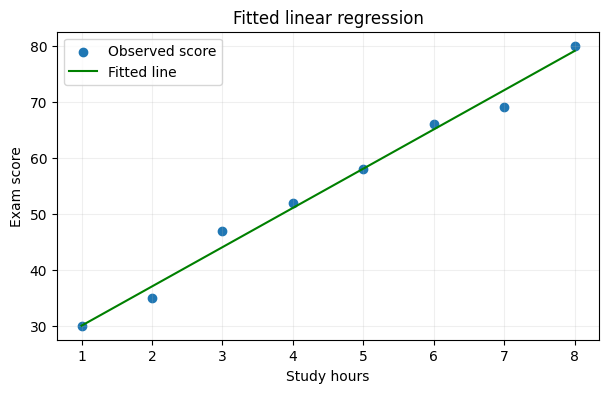

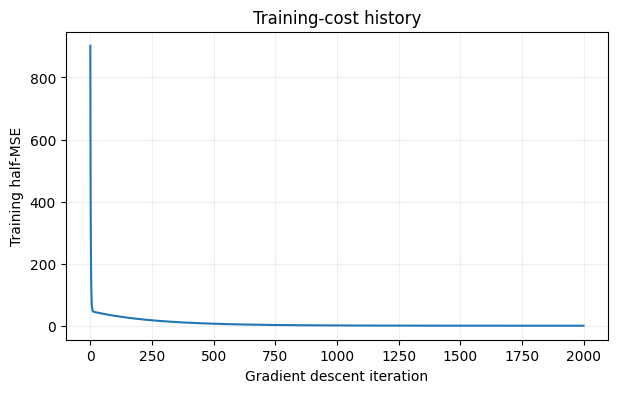

In [21]:
# Plot the learned line and the training-cost history.
x_line = np.linspace(hours.min(), hours.max(), 100)
plt.figure(figsize=(7, 4))
plt.scatter(hours, scores, label="Observed score")
plt.plot(x_line, w_fit * x_line + b_fit, color="green", label="Fitted line")
plt.xlabel("Study hours")
plt.ylabel("Exam score")
plt.title("Fitted linear regression")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Gradient descent iteration")
plt.ylabel("Training half-MSE")
plt.title("Training-cost history")
plt.grid(alpha=0.2)
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">نکته‌های کدِ نمودار</strong><div><ul>
<li><code>np.linspace(min,max,100)</code> صد نقطهٔ مرتب بین کمینه و بیشینهٔ ورودی می‌سازد تا خط صاف دیده شود.</li>
<li>فرمول <code>w_fit*x_line+b_fit</code> روی این صد مقدار اعمال می‌شود؛ نمودار سبز خروجی مدل <strong>بعد از آموزش</strong> است.</li>
<li><code>plt.plot(history)</code> مقدار هر هزینه را مقابل شمارهٔ تکرار رسم می‌کند.</li>
<li>اگر نمودار هزینه در انتها صاف شود، فقط نشان می‌دهد کاهش هزینه کوچک‌تر شده؛ به‌تنهایی ضمانت رسیدن به کمینهٔ دقیق نیست.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | نرخ یادگیری و واگرایی</strong><div><p>در این بخش تغییر اندازهٔ قدم را بررسی و مسیر جهش بین دو سوی یک دره را رسم می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">دو معنی کاملاً متفاوت برای alpha</strong><div><p>«اسم <code>alpha</code> را در چند جای نوت‌بوک می‌بینیم، ولی همیشه یک مفهوم نیست. <code>alpha</code> یا <code>learning_rate</code> در الگوریتم Gradient Descent طول قدم روی تابع هزینه را کنترل می‌کند. اما <code>plt.grid(alpha=0.2)</code> هیچ ربطی به آموزش مدل ندارد؛ اینجا <code>alpha</code> به معنی <strong>شفافیت/Opacity</strong> خطوط شبکهٔ نمودار است: ۰ کاملاً نامرئی، ۱ کاملاً پررنگ و ۰٫۲ یعنی تقریباً ۲۰٪ تیرگی.»</p><p>«<code>plt.grid()</code> خطوط راهنمای پس‌زمینه را فعال می‌کند. بنابراین عدد ۰٫۲ کیفیت مدل یا دقت محاسبه را تغییر نمی‌دهد؛ فقط کمک می‌کند محورهای نمودار را بخوانیم، بدون اینکه شبکه بیش‌ازحد توی چشم باشد.»</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">نرخ یادگیری، همگرایی و واگرایی</strong><div><p>چون هزینهٔ کمترین مربعات در مسئلهٔ خطی یک تابع درجه‌دو از پارامترهاست، نرخ یادگیری نامناسب ممکن است حرکت زیگزاگی شدید یا افزایش هزینه بدهد. بزرگی <strong>مقیاس ویژگی‌ها</strong> نیز روی نرخ یادگیری مناسب اثر می‌گذارد؛ برای همین در بخش بعدی همین زنگ استانداردسازی مهم خواهد شد. برای آزمایش نرخ‌های کوچک، مقدار ثابت شروع و تعداد گام یکسان بگذارید تا مقایسه منصفانه باشد.</p></div></div>

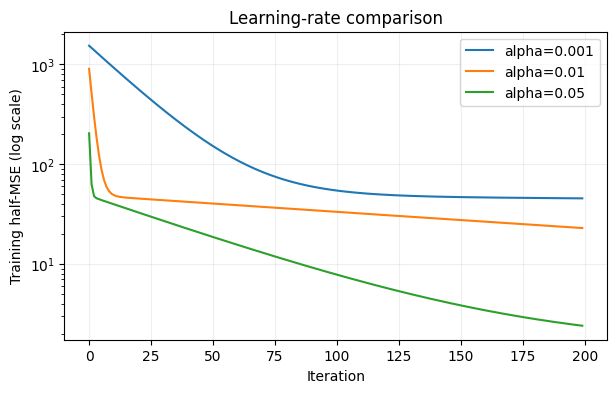

In [29]:
# Compare stable learning rates using the same initialization.
plt.figure(figsize=(7, 4))
for lr in [0.001, 0.01, 0.05]:
    _, _, costs = fit_simple_gd(hours, scores, learning_rate=lr, steps=200)
    plt.plot(costs, label=f"alpha={lr}")
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Training half-MSE (log scale)")
plt.title("Learning-rate comparison")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تفسیر نمودار نرخ یادگیری</strong><div><p><code>_ , _, costs</code> یعنی دو خروجی پارامتر را اینجا لازم نداریم و فقط تاریخچه را نگه می‌داریم. سه بار آموزش مستقل داریم، نه سه مرحلهٔ یک آموزش. <code>plt.yscale("log")</code> محور هزینه را لگاریتمی می‌کند؛ تفاوت درصدی مسیرها خواناتر می‌شود، اما صفر و مقادیر منفی روی این محور قابل رسم نیستند (هزینهٔ مربع‌ها منفی نیست). هر سه مسیر را با <strong>۴۰۰ تکرار</strong> مقایسه می‌کنیم؛ نتایج به داده و مقیاس وابسته‌اند.</p></div></div>

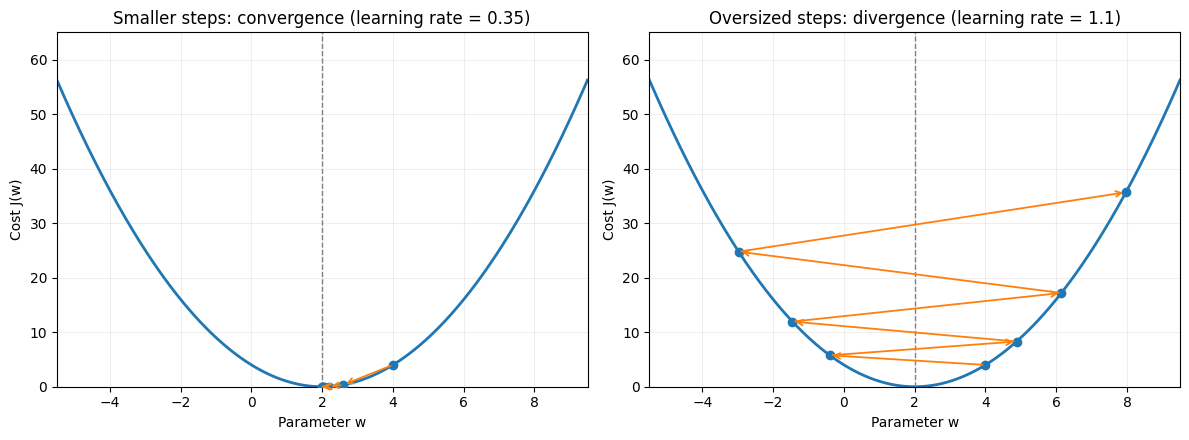

In [30]:
# Visualize gradient steps in a one-dimensional quadratic valley.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
weights = np.linspace(-5.5, 9.5, 500)
valley = (weights - 2.0) ** 2
for ax, lr, label in zip(axes, [0.35, 1.1], ["Smaller steps: convergence", "Oversized steps: divergence"]):
    w = 4.0
    path = [w]
    for _ in range(6):
        gradient = 2.0 * (w - 2.0)
        w = w - lr * gradient
        path.append(w)
    path = np.array(path)
    ax.plot(weights, valley, linewidth=2, label="J(w) = (w - 2)^2")
    ax.scatter(path, (path - 2.0) ** 2, s=36, zorder=3)
    for start, end in zip(path[:-1], path[1:]):
        ax.annotate("", xy=(end, (end-2.0)**2), xytext=(start, (start-2.0)**2),
                    arrowprops=dict(arrowstyle="->", lw=1.3, color="tab:orange"))
    ax.axvline(2, linestyle="--", linewidth=1, color="gray")
    ax.set_title(f"{label} (learning rate = {lr})")
    ax.set_xlabel("Parameter w")
    ax.set_ylabel("Cost J(w)")
    ax.set_xlim(-5.5, 9.5)
    ax.set_ylim(0, 65)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح قدم‌به‌قدم نمودار دره</strong><div><p>در این مثال آموزشی عمداً تابع سادهٔ <code>J(w)=(w−2)²</code> را انتخاب کرده‌ایم تا فقط یک پارامتر داشته باشیم. مشتق آن <code>2(w−2)</code> است و نقطهٔ کمینه <code>w=2</code>. هر تکرار فرمول <code>w = w − learning_rate × 2(w−2)</code> را اجرا می‌کند.</p><p>در شکل چپ نرخ ۰٫۳۵ مسیر را به کف دره نزدیک می‌کند. در شکل راست نرخ ۱٫۱ باعث می‌شود خط از کف عبور کند و به‌مرور فاصله‌اش بیشتر شود. در فرمول کلی ضریبِ فاصله از جواب پس از هر گام <code>(1−2α)</code> است: اگر قدر مطلقش کمتر از ۱ باشد به جواب نزدیک می‌شویم؛ اگر بیشتر باشد واگرا خواهیم شد. این <strong>فقط تحلیل همین تابع یک‌بعدی</strong> است و آستانهٔ ۱ برای تمام مسائل صادق نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #be185d;border-radius:8px;background:rgba(236,72,153,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">اشتباه متداول: نرخ بزرگ همیشه سریع‌تر نیست</strong><div><p>اگر <code>α</code> خیلی زیاد شود، ممکن است هزینه به‌جای کاهش بالا برود. برای نمایش واگرایی، <strong>ضروری نیست</strong> نرخ خیلی بالا را بدون کنترل روی دادهٔ اصلی اجرا کنید؛ ممکن است سرریز عددی ایجاد شود. کافی است در دفتر مسیر جهش از دو طرف یک دره را ترسیم کنید و بگویید «گام از شیب برمی‌آید ولی اندازه‌اش دست ماست».</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | دیتاست California Housing</strong><div><p>در چند سلول بعدی می‌فهمیم هر ردیف و هر ستون چه معنایی دارد، هدف در چه واحدی است و چگونه داده را می‌خوانیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">فرهنگ داده | معنی دقیق تک‌تک ۹ ستون</strong><div><table style="width:100%;border-collapse:collapse;text-align:right;direction:rtl"><thead><tr><th>ستون</th><th>تفسیر فارسی</th><th>نکتهٔ مهم</th></tr></thead><tbody>
<tr><td><code>MedInc</code></td><td>میانهٔ درآمد خانوارهای ناحیه، در واحد <strong>ده‌هزار دلار</strong></td><td>مثلاً ۸٫۳ یعنی حدود ۸۳ هزار دلار؛ «میانه» با «میانگین» متفاوت است.</td></tr>
<tr><td><code>HouseAge</code></td><td>میانهٔ سن ساختمان‌های مسکونی در ناحیه، به سال</td><td>مشخصهٔ یک خانهٔ منفرد نیست.</td></tr>
<tr><td><code>AveRooms</code></td><td>متوسط تعداد اتاق‌ها <strong>به ازای خانوار</strong></td><td>می‌تواند اعشاری باشد، چون میانگین است.</td></tr>
<tr><td><code>AveBedrms</code></td><td>متوسط تعداد اتاق‌خواب‌ها به ازای خانوار</td><td>از تعداد اتاق‌های کل متمایز است.</td></tr>
<tr><td><code>Population</code></td><td>جمعیت ساکن آن ناحیهٔ سرشماری</td><td>مقیاس آن با درآمد بسیار متفاوت است.</td></tr>
<tr><td><code>AveOccup</code></td><td>متوسط تعداد ساکنان به ازای خانوار</td><td>در برخی نواحی می‌تواند دادهٔ دورافتاده داشته باشد.</td></tr>
<tr><td><code>Latitude</code></td><td>عرض جغرافیایی ناحیه</td><td>موقعیت شمال/جنوب را توصیف می‌کند.</td></tr>
<tr><td><code>Longitude</code></td><td>طول جغرافیایی ناحیه</td><td>موقعیت شرق/غرب را توصیف می‌کند؛ اعداد اغلب منفی هستند.</td></tr>
<tr><td><code>MedHouseVal</code></td><td><strong>هدف:</strong> میانهٔ ارزش خانه‌ها در ناحیه، واحد ۱۰۰٬۰۰۰ دلار</td><td>نباید داخل <code>X</code> قرار بگیرد؛ آن را در <code>y</code> می‌گذاریم.</td></tr>
</tbody></table><p>پرسش کلاسی: چرا <code>AveRooms</code> ممکن است عدد ۴٫۸ باشد؟ چون مجموع اتاق‌ها را بر تعداد خانوارها تقسیم کرده‌ایم، نه اینکه یک خانهٔ خاص «۰٫۸ اتاق» داشته باشد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">شناخت دیتاست همراه نوت‌بوک</strong><div><p>فایل <code>california_housing.csv</code> از قبل داخل بسته است. خروجی <code>MedHouseVal</code> <strong>ارزش میانهٔ خانه در یک ناحیه</strong> بر حسب واحدهای <code>100,000</code> دلار است. ورودی‌ها هشت ستون عددی مثل <code>MedInc</code>، <code>HouseAge</code>، <code>AveRooms</code>، <code>Latitude</code> و <code>Longitude</code> هستند. داده تاریخی و تجمیعی است؛ ادعای قیمت‌گذاری دقیقِ یک ملک منفرد نداریم.</p>
<p>قبل از اجرای <code>describe</code> از خودتان بپرسید آیا مقیاس ستون‌ها شبیه هم است و آیا می‌توان بدون دیدن جدول فرض کرد همهٔ ستون‌ها دامنهٔ یکسان دارند؟</p></div></div>

In [31]:
# Load the included California housing dataset.
housing = pd.read_csv(DATA_DIR / "california_housing.csv")
print("Dataset shape:", housing.shape)
print("Column names:", housing.columns.tolist())
print("Total missing values:", int(housing.isna().sum().sum()))
display(housing.head())
display(housing.describe().round(2))

Dataset shape: (20640, 9)
Column names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Total missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مرور گام‌به‌گام کد CSV</strong><div><ul>
<li><code>pd.read_csv(...)</code> فایل متن جداشده با ویرگول را به DataFrame تبدیل می‌کند.</li>
<li><code>housing.shape</code> زوج <code>(تعداد سطر، تعداد ستون)</code> است؛ <code>housing.columns.tolist()</code> اسامی ستون‌ها را فهرست می‌کند.</li>
<li><code>housing.isna()</code> برای هر خانه می‌گوید خالی هست یا نه؛ <code>sum().sum()</code> ابتدا در ستون‌ها، سپس روی همهٔ ستون‌ها جمع می‌زند.</li>
<li><code>int(...)</code> عدد را به نوع صحیح پایتون تبدیل می‌کند.</li>
<li><code>head()</code> پنج سطر اول؛ <code>describe()</code> شاخص‌هایی مثل میانگین و چارک‌ها را روی ستون‌های عددی برمی‌گرداند؛ <code>round(2)</code> فقط نحوهٔ نمایش را تغییر می‌دهد.</li>
<li>سؤال: «۲۰۶۴۰ سطر یعنی ۲۰۶۴۰ خانهٔ منفرد؟» پاسخ: <strong>خیر، ردیف‌ها نمایندهٔ نواحی آماری‌اند.</strong></li>
</ul></div></div>

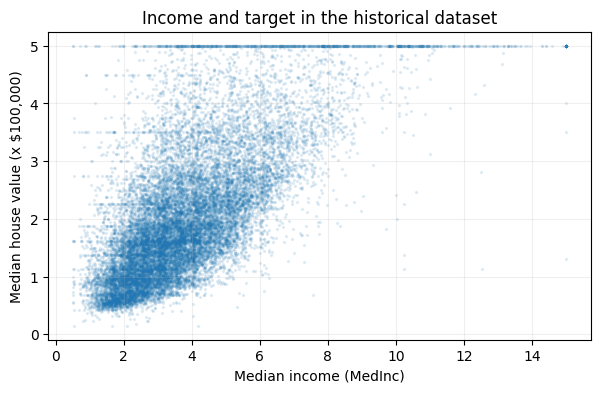

In [33]:
# Explore income versus the target without fitting any model.
plt.figure(figsize=(7, 4))
plt.scatter(housing["MedInc"], housing["MedHouseVal"], alpha=0.10, s=2)
plt.xlabel("Median income (MedInc)")
plt.ylabel("Median house value (x $100,000)")
plt.title("Income and target in the historical dataset")
plt.grid(alpha=0.2)
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">کد نمودار درآمد و خروجی</strong><div><p>دسترسی <code>housing["MedInc"]</code> یک ستون ورودی و <code>housing["MedHouseVal"]</code> یک ستون هدف را می‌دهد. <code>alpha=0.10</code> نقاط را کم‌رنگ می‌کند تا محل تراکم نقاط بهتر دیده شود؛ <code>s=8</code> اندازهٔ نقطه را کوچک می‌کند. وجود تراکم شدید نزدیک سقف خروجی از ویژگی‌های این داده است و می‌تواند خطاهای پیش‌بینی را تحت تأثیر قرار دهد؛ به نمودار دقت کنید و بی‌دلیل ادعای رابطهٔ علّی نکنید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">رگرسیون چندمتغیره؛ از یک x به یک بردار ویژگی</strong><div><p>اگر <code>p</code> ویژگی داشته باشیم، برای نمونهٔ <code>i</code> به جای یک <code>x_i</code>، بردار <code>x_i1, …, x_ip</code> داریم. به ازای هر ویژگی وزن جداگانه یاد می‌گیریم و یک بایاس به همه اضافه می‌کنیم. <strong>پاسخ هنوز یک عدد است.</strong> اگر <code>p=8</code> باشد، هشت وزن و یک بایاس خواهیم داشت. نام «چندمتغیره» اینجا یعنی چند <strong>ویژگی ورودی</strong>، نه چند خروجی هم‌زمان.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | ورود به مدل چندمتغیره</strong><div><p>دیگر برای هر سطر فقط یک x نداریم؛ با ماتریس X و بردار وزن‌ها، یک پیش‌بینی به ازای هر ردیف می‌سازیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

### فرمول اسکالرِ یک نمونه

$$
\hat y_i=\sum_{j=1}^{p}w_jx_{ij}+b
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جدول ابعاد؛ معنی n، p و w</strong><div><p><code>n</code> تعداد ردیف‌های آموزش و <code>p</code> شمار ویژگی‌هاست. در <code>X</code> هر سطر یک مشاهده و هر ستون یک ویژگی است. وزن‌ها یک بردار طول <code>p</code> هستند؛ ضرب داخلی هر سطر از <code>X</code> در <code>w</code>، یک نمره برای آن سطر می‌سازد. بایاس <code>b</code> به تمام این نمره‌ها اضافه می‌شود. اگر <code>X</code> ابعاد <code>(100,8)</code> و <code>w</code> ابعاد <code>(8,)</code> داشته باشد، <code>X@w</code> ابعاد <code>(100,)</code> دارد؛ نه <code>(8,100)</code> و نه یک عدد.</p></div></div>

### فرمول برداری تمام نمونه‌ها

$$
\underbrace{\hat{\mathbf y}}_{n\times1}=\underbrace{X}_{n\times p}\underbrace{\mathbf w}_{p\times1}+b\mathbf 1_n
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۷ | نمایش ماتریسی</strong><div><p>پیش‌بینی هر سه سطر ماتریس <code>X_small</code> را با یک ضرب ماتریسی و یک جمع بایاس به دست آورید. از حلقهٔ <code>for</code> استفاده نکنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [34]:
# Demonstrate matrix multiplication with three rows and two features.
X_small = np.array([[2.0, 1.0], [4.0, 2.0], [6.0, 1.0]])
w_small = np.array([3.0, -2.0])
b_small = 5.0
small_predictions = X_small @ w_small + b_small # TODO 07: Compute all predictions with matrix multiplication.
print("X shape:", X_small.shape)
print("w shape:", w_small.shape)
print("Predictions shape:", small_predictions.shape)
print("Predictions:", small_predictions)
print("First row by hand:", 2 * 3 + 1 * (-2) + 5)

X shape: (3, 2)
w shape: (2,)
Predictions shape: (3,)
Predictions: [ 9. 13. 21.]
First row by hand: 9


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | Train/Test و نشت داده</strong><div><p>می‌خواهیم بفهمیم مدل روی دادهٔ ندیده چطور عمل می‌کند؛ بنابراین داده‌ها را پیش از یادگیری پیش‌پردازش تقسیم می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح ماتریس کوچک</strong><div><ul>
<li><code>np.array([[...],[...],[...]])</code> آرایهٔ دوبعدی ۳×۲ می‌سازد؛ هر لیست داخلی یک سطر است.</li>
<li><code>w_small</code> دو وزن دارد؛ وزن دوم منفی است، پس با زیاد شدن ویژگی دوم و ثابت‌بودن اول، پیش‌بینی کاهش می‌یابد.</li>
<li><code>X_small @ w_small</code> یک بردار سه‌عضوی تولید می‌کند.</li>
<li><code>+ b_small</code> بایاس ۵ را به <strong>هر سه</strong> پیش‌بینی اضافه می‌کند.</li>
<li>حساب دستی سطر اول <code>2×3+1×(−2)+5=9</code> است و باید با خروجی نخست یکی باشد.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا باید آموزش و آزمون را جدا کنیم؟</strong><div><p>اگر روی همان نمونه‌هایی که پارامترهای مدل را تعیین کرده‌اند خطا بگیریم، ممکن است توانایی مدل روی دادهٔ تازه را بیش‌برآورد کنیم. دادهٔ <strong>Train</strong> برای یادگرفتن <code>w,b</code> است و دادهٔ <strong>Test</strong> برای ارزیابی نهاییِ مستقل. هنگام انتخاب مدل یا تنظیم ابرپارامترها باید بخش اعتبارسنجی (Validation) جدا یا Cross-Validation داشته باشیم. در این درس، نرخ یادگیری را با بررسی همگرایی روی <strong>Train</strong> آموزش می‌دهیم و از <strong>Test</strong> برای انتخاب نرخ یادگیری استفاده نمی‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #be185d;border-radius:8px;background:rgba(236,72,153,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">هشدار علمی: Data Leakage</strong><div><p>نشت داده یعنی اطلاعاتی که هنگام پیش‌بینی واقعی در دسترس نیست، به هر شکلی وارد ساخت مدل شود؛ مثلاً استانداردسازی را قبل از جداسازی روی <strong>کل داده</strong> <code>fit</code> کنیم و از آمار آزمون استفاده کنیم. تفاوت مهم: استفاده از <strong>ویژگی‌های Test برای پیش‌بینی</strong> مجاز است، ولی یادگرفتن میانگین، انحراف معیار یا پارامترها از Test برای ارزیابی مستقل مجاز نیست.</p></div></div>

In [35]:
# Split feature columns from the target and keep paired rows together.
feature_names = [column for column in housing.columns if column != "MedHouseVal"]
X_raw = housing[feature_names].to_numpy(dtype=float)
y_raw = housing["MedHouseVal"].to_numpy(dtype=float)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=SEED
)
print("Features:", feature_names)
print("Train shapes:", X_train_raw.shape, y_train.shape)
print("Test shapes:", X_test_raw.shape, y_test.shape)
print("Feature count:", X_train_raw.shape[1])

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Train shapes: (16512, 8) (16512,)
Test shapes: (4128, 8) (4128,)
Feature count: 8


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">شرح سطرهای تقسیم داده</strong><div><ul>
<li>لیست <code>feature_names</code> با List Comprehension تمام نام ستون‌ها به‌جز هدف را برمی‌دارد. اگر هدف را وارد <code>X</code> کنیم <strong>Target Leakage</strong> داریم.</li>
<li><code>housing[feature_names]</code> فقط ویژگی‌ها را به شکل جدول می‌گیرد؛ <code>.to_numpy(dtype=float)</code> آن را به ماتریس عددی تبدیل می‌کند.</li>
<li><code>housing["MedHouseVal"]</code> بردار <code>y</code> است.</li>
<li><code>train_test_split(X_raw,y_raw,...)</code> <strong>ردیف‌های متناظر</strong> را با هم جابه‌جا می‌کند؛ <code>test_size=0.20</code> یعنی ۲۰٪ برای آزمون.</li>
<li><code>random_state=SEED</code> تقسیم تکرارپذیر می‌دهد؛ ثابت‌بودن بذر <strong>کیفیت مدل را تضمین نمی‌کند</strong>.</li>
<li><code>X_train_raw.shape[1]</code> تعداد ستون‌ها یعنی <code>p</code> را نشان می‌دهد؛ <code>shape[0]</code> تعداد ردیف‌هاست.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | استانداردسازی و ddof</strong><div><p>در این بخش میانگین و انحراف معیار هر ستون را فقط از Train یاد می‌گیریم و تفاوت ddof=0 و ddof=1 را روشن می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ddof چیست؟ مسئلهٔ «چرا n یا n−1؟»</strong><div><p><strong><code>ddof</code></strong> مخفف <em>Delta Degrees of Freedom</em> است و در <code>np.std</code> می‌گوید در مخرجِ محاسبهٔ واریانس از <code>n − ddof</code> استفاده کنیم. <code>ddof=0</code> (پیش‌فرض NumPy) یعنی مخرج n؛ برای استانداردسازی مجموعهٔ موجود و نیز رویهٔ <code>StandardScaler</code> همین قرارداد به کار می‌رود. <code>ddof=1</code> یعنی مخرج n−1؛ معمولاً هنگام برآورد واریانس جامعه از یک نمونه برای تصحیح سوگیری واریانس نمونه‌ای استفاده می‌شود.</p><p><strong>نکتهٔ دقیق:</strong> تقسیم بر n−1 واریانس نمونه را تحت فرض‌های معمول بدون‌سوگیری می‌کند، اما خود <strong>انحراف معیارِ</strong> حاصل الزاماً بدون‌سوگیری نیست. این دو را یکی نگیریم. اگر n=1 باشد، <code>ddof=1</code> مخرج صفر ایجاد می‌کند.</p></div></div>

### فرمول دو قرارداد انحراف معیار

$$
\bar x=\frac1n\sum_{i=1}^{n}x_i,\qquad
s_{\mathrm{ddof}=d}=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar x)^2}{n-d}}.
$$

In [36]:
# Compare population and sample standard deviations on a tiny array.
small_values = np.array([10.0, 20.0, 30.0])
print("Mean:", small_values.mean())
print("Std with ddof=0:", small_values.std(ddof=0))
print("Std with ddof=1:", small_values.std(ddof=1))
print("Number of observations:", small_values.size)

Mean: 20.0
Std with ddof=0: 8.16496580927726
Std with ddof=1: 10.0
Number of observations: 3


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح کد ddof</strong><div><p><code>small_values</code> سه عدد دارد؛ <code>mean()</code> میانگین ۲۰ را می‌سازد. در <code>std(ddof=0)</code> مجموع مجذور انحراف‌ها بر ۳ تقسیم می‌شود، در <code>std(ddof=1)</code> بر ۲. دستور <code>size</code> تعداد اعضا را نشان می‌دهد و هیچ ارتباطی با تعداد ستون‌های دیتاست مسکن ندارد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا ویژگی‌ها را استاندارد می‌کنیم؟</strong><div><p>متراژ، درآمد و عرض جغرافیایی دامنه‌های عددی متفاوتی دارند. در Gradient Descent اگر ویژگی‌های مقیاس بزرگ و کوچک کنار هم باشند، هزینه در بعضی جهت‌ها بسیار تندتر از بعضی جهت‌های دیگر تغییر می‌کند و انتخاب یک نرخ یادگیری مناسب دشوارتر می‌شود. در <strong>Z-score</strong> از هر ستون میانگین آموزش را کم و بر انحراف معیار همان ستون تقسیم می‌کنیم. هدف کاهش مشکلِ تفاوت مقیاس در فرایند بهینه‌سازی است؛ استانداردسازی <strong>به‌خودی‌خود</strong> رابطهٔ جدیدی در داده کشف نمی‌کند.</p></div></div>

### فرمول استانداردسازی

$$
z_{ij}=\frac{x_{ij}-\mu_j^{\mathrm{train}}}{\sigma_j^{\mathrm{train}}}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مثال عددی و نکتهٔ انحراف معیار صفر</strong><div><p>اگر یک ستون Train برابر <code>[10,20,30]</code> باشد، میانگین <code>20</code> و انحراف معیار جمعیت با قرارداد <code>ddof=0</code> برابر <code>sqrt(200/3)≈8.165</code> است؛ عدد ۱۰ پس از تبدیل حدود <code>−1.225</code> می‌شود. لازم نیست ستون Test میانگین صفر داشته باشد؛ چون <strong>آمار Train</strong> برای تبدیل Test استفاده می‌شود. اگر انحراف معیار یک ستون صفر باشد، تقسیم بر صفر رخ می‌دهد. در کد، برای آن ستون به‌جای انحراف معیار صفر از ۱ استفاده می‌کنیم تا تبدیل از نظر عددی تعریف شود؛ آن ستون روی آموزش پس از کم‌کردن میانگین ثابت صفر است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۸ | استانداردسازی بدون Data Leakage</strong><div><p>میانگین و انحراف معیار را فقط از <code>X_train_raw</code> محاسبه کنید و سپس همان آمار را برای استانداردسازی Train و Test به کار ببرید. برای ستون با انحراف معیار صفر از مقدار امن استفاده می‌کنیم.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [39]:
# Fit scaling statistics on training data only.
train_mean = X_train_raw.mean(axis=0)  # TODO 08a: Column means from training data only.
train_std = X_train_raw.std(axis=0)  # TODO 08b: Column standard deviations from training data only.
train_std_safe = np.where(train_std == 0, 1.0, train_std)

# Apply the same training-derived transformation to both splits.
X_train = (X_train_raw - train_mean) / train_std_safe  # TODO 08c: Standardize the training features.
X_test = (X_test_raw - train_mean) / train_std_safe   # TODO 08d: Transform test features with training statistics.

print("Scaled training means:", X_train.mean(axis=0).round(3))
print("Scaled training standard deviations:", X_train.std(axis=0).round(3))
print("Scaled shapes:", X_train.shape, X_test.shape)

Scaled training means: [-0. -0.  0. -0. -0. -0.  0. -0.]
Scaled training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1.]
Scaled shapes: (16512, 8) (4128, 8)


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جزئیات کد استانداردسازی</strong><div><ul>
<li><code>mean(axis=0)</code> روی سطرهای <strong>هر ستون</strong> میانگین می‌گیرد، پس خروجی طول <code>p</code> دارد. <code>axis=1</code> برعکس، میانگین هر سطر را می‌گیرد و اینجا اشتباه است.</li>
<li><code>std(axis=0)</code> انحراف معیار هر ستون را می‌دهد؛ تنظیم پیش‌فرض NumPy یعنی <code>ddof=0</code> است.</li>
<li><code>np.where(train_std==0,1.0,train_std)</code> برای جلوگیری از تقسیم بر صفر عمل می‌کند.</li>
<li>در <code>(X_train_raw-train_mean)</code> با سازوکار <strong>broadcasting</strong>، بردار میانگین از هر سطر ماتریس کم می‌شود.</li>
<li><strong>مهم:</strong> در ساخت <code>X_test</code> به جای <code>X_test_raw.mean(...)</code> از همان <code>train_mean</code> و <code>train_std_safe</code> استفاده شده.</li>
<li><code>.round(3)</code> برای چاپِ فشرده است، نه تغییر مقدار واقعی آرایه.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پرسش‌های مرور بخش دوم</strong><div><p>۱) برای هزینهٔ Half-MSE، مشتق نسبت به <code>b</code> چرا عامل <code>x</code> ندارد؟<br/>
۲) اگر <code>dw=−4</code> و <code>α=0.2</code> باشد، مقدار <code>w</code> پس از یک گام چند واحد عوض می‌شود؟<br/>
۳) در این نوت‌بوک چرا <code>history[0]</code> لزوماً همان هزینهٔ قبل از آموزش نیست؟</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | گرادیان برداری</strong><div><p>ریاضیات مدل چندمتغیره را به فرمول X.T @ errors و حلقهٔ NumPy تبدیل می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">بخش ۳ | رگرسیون چندمتغیره، OLS و ارزیابی</strong><div><p>فرمول گرادیان برداری، معادلهٔ نرمال، شبه‌معکوس مور–پنروز، مدل آمادهٔ Scikit-Learn، چهار معیار خطا و مدل مبنای DummyRegressor را مطالعه می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">گرادیان برداریِ چندمتغیره</strong><div><p>اکنون <code>w</code> برداری با <code>p</code> عضو است؛ باقی‌مانده برای همهٔ ردیف‌ها <code>r=Xw+b1−y</code> خواهد بود. مشتق نسبت به تک‌تک وزن‌ها برابر <code>Σ r_i x_ij / m</code> است. این <code>p</code> مقدار را می‌توان هم‌زمان با ضرب ماتریسی <code>X.T @ r</code> حساب کرد. شکل‌ها را <strong>قبل از اجرا</strong> در دفتر بنویسید: <code>X.T</code> برابر <code>(p,m)</code>، <code>r</code> برابر <code>(m,)</code>، حاصل برابر <code>(p,)</code>.</p>
<p>بایاس همچنان یک عدد است و مشتقش میانگین باقی‌مانده‌هاست.</p></div></div>

### هزینه و گرادیان برداری

$$
\begin{aligned}
\mathbf r &=X\mathbf w+b\mathbf 1-\mathbf y\\
J(\mathbf w,b)&=\frac{1}{2m}\mathbf r^{\mathsf T}\mathbf r\\
\nabla_{\mathbf w}J&=\frac{1}{m}X^{\mathsf T}\mathbf r,\qquad \frac{\partial J}{\partial b}=\frac{1}{m}\mathbf 1^{\mathsf T}\mathbf r
\end{aligned}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۹ | گرادیان چندمتغیره</strong><div><p>در سه تابع زیر، هزینهٔ Half-MSE، گرادیان وزن‌ها با <code>X.T @ errors</code> و یک گام به‌روزرسانی بردار وزن‌ها را کامل کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [41]:
# Implement vectorized half-MSE and its gradient.
def cost_multi(X, y, w, b):
    errors = X @ w + b - y
    return np.mean(errors ** 2) / 2  # TODO 09a: Return the vectorized half-MSE.


def gradient_multi(X, y, w, b):
    m = X.shape[0]
    errors = X @ w + b - y
    dw = (X.T @ errors) / m  # TODO 09b: Compute the vector gradient.
    db = errors.mean()  # TODO 09c: Compute the intercept gradient.
    return dw, db


def train_multi_gd(X, y, alpha=0.05, steps=1200):
    w = np.zeros(X.shape[1])
    b = 0.0
    costs = []
    for _ in range(steps):
        dw, db = gradient_multi(X, y, w, b)
        w = w - alpha * dw # TODO 09d: Update all feature weights.
        b = b - alpha * db  # TODO 09e: Update the intercept.
        costs.append(cost_multi(X, y, w, b))
    return w, b, np.array(costs)

w_gd, b_gd, multi_history = train_multi_gd(X_train, y_train)
pred_gd = X_test @ w_gd + b_gd
print("Weight vector shape:", w_gd.shape)
print("Training cost, first and last:", multi_history[0], multi_history[-1])

Weight vector shape: (8,)
Training cost, first and last: 2.570522657802766 0.25899169739024114


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">شرح تفصیلی سه تابع چندمتغیره</strong><div><ul>
<li><code>cost_multi</code>: <code>X@w</code> به ازای هر ردیف یک عدد تولید می‌کند، <code>+b</code> آن را جابه‌جا می‌کند و <code>−y</code> باقی‌مانده را می‌دهد؛ خروجی تابع هزینه <strong>یک عدد</strong> است.</li>
<li><code>gradient_multi</code>: <code>m=X.shape[0]</code> تعداد نمونه‌هاست؛ <code>X.T@errors</code> هشت مشتق خامِ جمع‌شده می‌دهد؛ تقسیم بر <code>m</code> میانگین می‌کند؛ <code>db=errors.mean()</code> مشتق بایاس است.</li>
<li><code>np.zeros(X.shape[1])</code>: به تعداد ویژگی‌ها وزن صفر می‌سازد. اگر به اشتباه <code>X.shape[0]</code> بنویسیم، تعداد وزن‌ها برابر تعداد سطرها می‌شود و ضرب ماتریسی خطا می‌دهد.</li>
<li>در حلقه، <code>dw</code> آرایهٔ هشت‌تایی و <code>db</code> یک عدد است؛ عمل <code>w-alpha*dw</code> هر هشت وزن را هم‌زمان تغییر می‌دهد.</li>
<li><code>pred_gd=X_test@w_gd+b_gd</code> <strong>آموزش نیست</strong>؛ از وزن‌های به‌دست‌آمده برای پیش‌بینی آزمون استفاده می‌کنیم. خطای آزمون را برای مقایسهٔ نهایی در بخش چهارم محاسبه خواهیم کرد.</li>
<li><code>costs</code> فقط هزینهٔ Train را ثبت می‌کند و آن را به عنوان معیار انتخاب نرخ یادگیری مشاهده می‌کنیم؛ Test وارد آموزش یا تنظیم گام‌ها نشده است.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">نمودار یادگیری چندمتغیره را تحلیل کن</strong><div><p>اگر منحنی ابتدا سریع و سپس کند پایین می‌آید، علتش کاهش اندازهٔ تغییرات مؤثر در نزدیکی کمینه است. پرسش: آیا انتظار داریم MSE روی Test دقیقاً نصف عددِ محور باشد؟ پاسخ: خیر؛ محور <strong>هزینهٔ Train = نصف MSE روی Train</strong> است و مجموعهٔ آزمون جداست.</p></div></div>

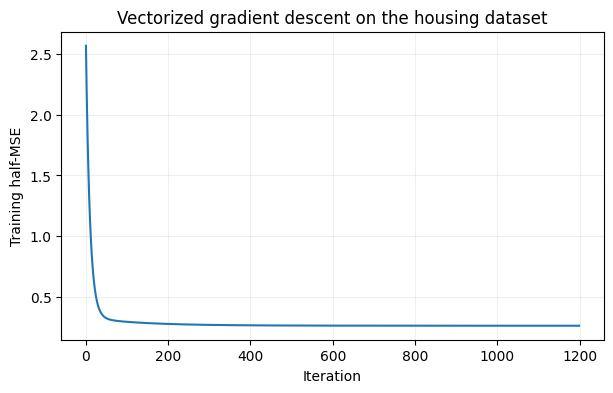

In [42]:
# Inspect the training-cost curve for the multivariable model.
plt.figure(figsize=(7, 4))
plt.plot(multi_history)
plt.xlabel("Iteration")
plt.ylabel("Training half-MSE")
plt.title("Vectorized gradient descent on the housing dataset")
plt.grid(alpha=0.2)
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">نکتهٔ یک‌سلولی</strong><div><p><code>multi_history</code> یک آرایهٔ یک‌بعدی به طول تعداد گام‌هاست. چون در هر گام فقط Train به <code>cost_multi</code> داده شده، این نمودار <strong>Learning Curve روی تکرارهای Train</strong> است، نه نمودار عملکرد روی دادهٔ آزمون یا نمودار Train/Validation.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | معادلهٔ نرمال و مور–پنروز</strong><div><p>اکنون به‌جای تکرار گرادیان، جواب کمترین مربعات را با معادلات خطی و شبه‌معکوس به دست می‌آوریم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">آیا بدون قدم‌های گرادیان می‌توان جواب پیدا کرد؟</strong><div><p>برای کمترین مربعات، می‌توان پارامترها را با یک مسئلهٔ جبر خطی به دست آورد. ستونِ یک‌ها را به <code>X</code> اضافه می‌کنیم تا <code>b</code> نیز یکی از اجزای بردار پارامتر <code>θ</code> باشد. با مشتق‌گرفتن از خطای مربعی نسبت به <code>θ</code> و برابر صفر قرار دادن آن، به معادلهٔ نرمال می‌رسیم. برای استفاده از وارون معمولی باید <code>XᵀX</code> وارون‌پذیر باشد؛ در کاربرد عملی، <strong>شبه‌معکوس</strong> یا حل‌کننده‌های عددی پایدارتر از تشکیل وارون صریح هستند.</p></div></div>

### شکل معادلهٔ نرمال

$$
\begin{aligned}
\tilde X &= [\mathbf 1\; X],\\
\tilde X^{\mathsf T}\tilde X\,\theta&=\tilde X^{\mathsf T}\mathbf y,\\
\hat\theta&=(\tilde X^{\mathsf T}\tilde X)^{-1}\tilde X^{\mathsf T}\mathbf y\quad\text{(اگر وارون‌پذیر باشد)}
\end{aligned}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">شبه‌معکوس مور–پنروز دقیقاً چیست؟</strong><div><p><strong>۱) معکوس معمولی:</strong> برای ماتریس مربعیِ وارون‌پذیر A، ماتریس A⁻¹ داریم که A⁻¹A=AA⁻¹=I. اما ماتریس دادهٔ X معمولاً مستطیلی است؛ حتی اگر مربعی باشد ممکن است ستون‌های وابسته داشته باشد. در این صورت وارون معمولی وجود ندارد.</p><p><strong>۲) شبه‌معکوس:</strong> برای هر ماتریس حقیقی X، <strong>یک ماتریس یکتای Moore–Penrose</strong> با نماد X⁺ وجود دارد. اگر دستگاه Xθ=y دقیقاً حل‌پذیر نباشد، بردار <strong>θ=X⁺y</strong> مجموع مربعات خطا را کمینه می‌کند؛ اگر چند جوابِ کمترین مربعات داشته باشیم، از میان آنها جوابی با <strong>کمترین اندازهٔ اقلیدسی ضرایب</strong> انتخاب می‌شود.</p><p><strong>۳) ساخت با SVD:</strong> X را به صورت <code>U Σ Vᵀ</code> تجزیه می‌کنیم؛ سپس برای ساخت X⁺ مقدارهای منفردِ غیرصفر را معکوس می‌کنیم و جای ماتریس‌ها را متناسب با فرمول عوض می‌کنیم. مقادیر صفر یا از نظر عددی بسیار کوچک را وارونه نمی‌کنیم. <code>np.linalg.pinv(X)</code> این فرایند را با آستانهٔ عددی پیاده می‌کند.</p><p><strong>۴) برداشت اشتباه:</strong> شبه‌معکوس همهٔ مشکلات داده را از بین نمی‌برد؛ فقط یک پاسخ ریاضیِ مشخص به مسئلهٔ Least Squares می‌دهد. هم‌خطی شدید همچنان می‌تواند تفسیر ضرایب را ناپایدار کند.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.38);border-right:5px solid #0891b2;border-radius:12px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.0;color:inherit;"><div style="font-weight:750;font-size:1.13em;margin:0 0 5px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#0891b2;border-radius:50%;margin-left:8px;"></span>تعریف عملی و فرمول SVD برای شبه‌معکوس مور–پنروز</div><p style="margin:4px 0 8px;">این روابط نشان می‌دهند چگونه با کمک <strong>Singular Value Decomposition (SVD)</strong>، شبه‌معکوس ساخته می‌شود و سپس ضرایب رگرسیون را به دست می‌آوریم.</p><div dir="ltr" style="direction:ltr;text-align:center;overflow-x:auto;background:rgba(148,163,184,.07);border:1px solid rgba(148,163,184,.19);border-radius:9px;padding:12px 8px;line-height:1.4;margin:12px 0;"><math style="margin:8px auto;" xmlns="http://www.w3.org/1998/Math/MathML" display="block" aria-label="X equals U Sigma V transpose">
 <mrow><mi>X</mi><mo>=</mo><mi>U</mi><mi>Σ</mi><msup><mi>V</mi><mi mathvariant="normal">T</mi></msup></mrow>
</math>
<math style="margin:8px auto;" xmlns="http://www.w3.org/1998/Math/MathML" display="block" aria-label="X pseudo inverse equals V Sigma pseudo inverse U transpose">
 <mrow><msup><mi>X</mi><mo>+</mo></msup><mo>=</mo><mi>V</mi><msup><mi>Σ</mi><mo>+</mo></msup><msup><mi>U</mi><mi mathvariant="normal">T</mi></msup></mrow>
</math>
<math style="margin:8px auto;" xmlns="http://www.w3.org/1998/Math/MathML" display="block" aria-label="theta hat equals X pseudo inverse times y">
 <mrow><mover accent="true"><mi>θ</mi><mo>ˆ</mo></mover><mo>=</mo><msup><mi>X</mi><mo>+</mo></msup><mi>y</mi></mrow>
</math></div><p style="margin:6px 0 0;">در تجزیهٔ SVD، ماتریس <code>X</code> به سه عامل تجزیه می‌شود. در <span dir="ltr" style="display:inline-block;vertical-align:middle;"><math xmlns="http://www.w3.org/1998/Math/MathML"><msup><mi>Σ</mi><mo>+</mo></msup></math></span>، برای هر مقدار منفردِ غیرصفرِ <span dir="ltr" style="display:inline-block;vertical-align:middle;"><math xmlns="http://www.w3.org/1998/Math/MathML"><msub><mi>σ</mi><mi>i</mi></msub></math></span>، از معکوس آن یعنی <span dir="ltr" style="display:inline-block;vertical-align:middle;"><math xmlns="http://www.w3.org/1998/Math/MathML"><mfrac><mn>1</mn><msub><mi>σ</mi><mi>i</mi></msub></mfrac></math></span> استفاده می‌کنیم؛ برای مقدار منفردِ صفر، صفر می‌گذاریم. در محاسبات عددی، مقدارهای <strong>بسیار کوچک</strong> نیز بر اساس آستانهٔ تحمل عددی، عملاً صفر در نظر گرفته می‌شوند. به همین علت، شبه‌معکوس حتی وقتی معکوس معمولی وجود ندارد، می‌تواند برای محاسبهٔ جواب کمترین مربعات به کار برود.</p></div>

In [43]:
# Show a rank-deficient matrix with two identical columns.
X_duplicate = np.array([[1., 1.], [2., 2.], [3., 3.]])
y_duplicate = np.array([2., 4., 6.])
coef_duplicate = np.linalg.pinv(X_duplicate) @ y_duplicate
print("Matrix shape and rank:", X_duplicate.shape, np.linalg.matrix_rank(X_duplicate))
print("Minimum-norm coefficients:", coef_duplicate)
print("Predictions:", X_duplicate @ coef_duplicate)
print("Other valid coefficients:", X_duplicate @ np.array([2., 0.]))

Matrix shape and rank: (3, 2) 1
Minimum-norm coefficients: [1. 1.]
Predictions: [2. 4. 6.]
Other valid coefficients: [2. 4. 6.]


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خط‌به‌خط مثال شبه‌معکوس</strong><div><p><code>X_duplicate</code> ماتریسی ۳×۲ است که رتبهٔ آن فقط ۱ است؛ چون ستون دوم مستقل از ستون اول نیست. <code>matrix_rank</code> تعداد جهت‌های مستقل را گزارش می‌دهد. <code>pinv(X_duplicate)</code> یک ماتریس ۲×۳ می‌سازد؛ ضرب آن در بردار سه‌عضوی y دو ضریب برمی‌گرداند. خروجی ضرایب نزدیک [۱،۱] است. خطوط آخر نشان می‌دهند ضرایب متفاوت هم می‌توانند همهٔ پیش‌بینی‌ها را یکسان بسازند.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">شبه‌معکوس کجا وارد می‌شود؟</strong><div><p>فرمول بستهٔ ساده فقط وقتی مستقیم قابل استفاده است که وارون وجود داشته باشد. حتی در این حالت ساختن <code>XᵀX</code> می‌تواند مشکل عددی را بیشتر کند. <code>np.linalg.pinv(	ilde X) @ y</code> با شبه‌معکوس مور–پنروز جواب کمترین مربعات را حتی در حالت وابستگی خطی ستون‌ها می‌یابد؛ در حالت جواب‌های متعدد، جواب با کمترین نُرم را برمی‌گرداند. پس این روش و Gradient Descent <strong>دو مسیر محاسباتی</strong> برای کمینه‌سازی یک هزینه‌اند، نه دو نوع مسئلهٔ متفاوت.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۰ | شبه‌معکوس</strong><div><p>یک ستونِ ۱ به ماتریس ویژگی‌ها اضافه شده است. با <code>np.linalg.pinv</code> بردار پارامتر را به دست آورید، سپس بایاس و بردار وزن را جدا کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [44]:
# Solve least squares with a numerically robust pseudo-inverse.
X_train_with_bias = np.column_stack([np.ones(len(X_train)), X_train])
theta_closed = np.linalg.pinv(X_train_with_bias) @ y_train # TODO 10: Solve least squares with the Moore-Penrose pseudo-inverse.
b_closed = theta_closed[0]
w_closed = theta_closed[1:]
pred_closed = X_test @ w_closed + b_closed

print("Augmented matrix shape:", X_train_with_bias.shape)
print("Closed-form parameter count:", len(theta_closed))
print("Largest GD / pseudo-inverse prediction gap:",
      float(np.max(np.abs(pred_gd - pred_closed))))

Augmented matrix shape: (16512, 9)
Closed-form parameter count: 9
Largest GD / pseudo-inverse prediction gap: 0.04768110921280089


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">جزئیات کدِ شبه‌معکوس</strong><div><ul>
<li><code>np.ones(len(X_train))</code> برداری از ۱ به طول تعداد نمونه‌های Train می‌سازد.</li>
<li><code>np.column_stack([...])</code> آن را به عنوان ستون اول به ماتریس اضافه می‌کند؛ اگر ۸ ویژگی داشتیم، اکنون <strong>۹ ستون</strong> داریم.</li>
<li><code>np.linalg.pinv</code> شبه‌معکوس ماتریس را محاسبه می‌کند؛ <code>@ y_train</code> ضرایب کمترین مربعات را استخراج می‌کند.</li>
<li><code>theta_closed[0]</code> بایاس و <code>theta_closed[1:]</code> هشت وزن است.</li>
<li>در پیش‌بینی Test از نسخهٔ <strong>بدون ستون یک</strong> استفاده می‌کنیم چون <code>b_closed</code> را جدا جمع می‌کنیم؛ اگر دوباره ستون بایاس بدهیم و جدا هم جمع کنیم، دوبار حساب می‌شود.</li>
<li><code>np.abs(pred_gd-pred_closed)</code> اختلاف قدرمطلق پیش‌بینی‌ها را برای هر ردیف می‌گیرد و <code>max</code> بزرگ‌ترین را چاپ می‌کند؛ اختلاف صفرِ کامل انتظار نداشته باشید.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چهار گام معمول در API یادگیری ماشین</strong><div><p>۱) <code>model = LinearRegression()</code> فقط شیء مدل را می‌سازد. ۲) <code>model.fit(X_train,y_train)</code> ضرایب را از <strong>Train</strong> یاد می‌گیرد. ۳) <code>model.predict(X_test)</code> با ضرایب آموزش‌دیده پیش‌بینی انجام می‌دهد. ۴) معیار خطا پیش‌بینی‌ها را با <code>y_test</code> مقایسه می‌کند. <code>coef_</code> بردار وزن‌ها و <code>intercept_</code> بایاس یادگرفته‌شده هستند. خط زیرِ انتهای نام ویژگی‌ها در Scikit-Learn معمولاً نشان می‌دهد آن ویژگی <strong>پس از fit</strong> ایجاد شده است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | OLS در Scikit-Learn</strong><div><p>در چند سلول بعدی یک LinearRegression می‌سازیم، آن را fit می‌کنیم و روی Test با روش‌های دستی مقایسه می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">Ordinary Least Squares (OLS) را از اسمش بفهمیم</strong><div><p><strong>Ordinary</strong> یعنی شکل معمول/بدون وزن‌دهی ویژه؛ <strong>Least</strong> یعنی کمینه‌کردن؛ و <strong>Squares</strong> یعنی مربع باقی‌مانده‌ها. پس OLS مسئله‌ای است که ضرایب را طوری برمی‌گزیند که <code>Σ(y − ŷ)²</code> کمترین باشد. معمولاً فرض نمی‌کنیم هر نقطه دقیقاً روی خط می‌افتد.</p><p><strong>تفاوت هدف و روش:</strong> OLS «هدفِ ریاضی» است؛ <code>np.linalg.pinv</code> یک راه عددی برای حل آن و <code>LinearRegression</code> یک API آماده برای محاسبهٔ همین برازش است؛ <code>Gradient Descent</code> هم می‌تواند همان هدف را با گام‌های تکراری تقریب بزند. بنابراین OLS <strong>نام دیگر Gradient Descent نیست</strong>.</p><p><strong>پرسش احتمالی:</strong> «آیا OLS همیشه پیش‌بینی فوق‌العاده می‌دهد؟» خیر؛ فقط بهترین جواب در خانوادهٔ خطی نسبت به خطای مربعی روی دادهٔ آموزش را هدف می‌گیرد. اگر الگوی رابطه غیرخطی یا داده نویزی باشد، خطا می‌تواند قابل توجه بماند.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:12px 0 14px 10px;padding:17px 20px;border:1px solid rgba(148,163,184,.38);border-right:5px solid #7c3aed;border-radius:12px;background:rgba(124,58,237,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:2.0;color:inherit;"><div style="font-weight:750;font-size:1.13em;margin:0 0 5px 0;color:inherit;"><span aria-hidden="true" style="display:inline-block;width:9px;height:9px;background:#7c3aed;border-radius:50%;margin-left:8px;"></span>هدف روش کمترین مربعات معمولی (Ordinary Least Squares — OLS)</div><p style="margin:4px 0 8px;">این فرمول، <strong>مسئلهٔ بهینه‌سازی</strong> را تعریف می‌کند؛ به‌خودیِ خود الگوریتم حل نیست. نماد <code>argmin</code> یعنی «آن مقدار از پارامترها را پیدا کن که عبارت بعد از آن کمینه شود».</p><div dir="ltr" style="direction:ltr;text-align:center;overflow-x:auto;background:rgba(148,163,184,.07);border:1px solid rgba(148,163,184,.19);border-radius:9px;padding:12px 8px;line-height:1.4;margin:12px 0;"><math style="margin:8px auto;" xmlns="http://www.w3.org/1998/Math/MathML" display="block" aria-label="theta hat OLS equals arg min theta of norm X theta minus y squared">
 <mrow>
  <msub><mover accent="true"><mi>θ</mi><mo>ˆ</mo></mover><mtext>OLS</mtext></msub>
  <mo>=</mo>
  <munder><mo movablelimits="true">arg min</mo><mi>θ</mi></munder>
  <msubsup>
   <mrow><mo>‖</mo><mi>X</mi><mi>θ</mi><mo>−</mo><mi>y</mi><mo>‖</mo></mrow>
   <mn>2</mn><mn>2</mn>
  </msubsup>
 </mrow>
</math>
<math style="margin:8px auto;" xmlns="http://www.w3.org/1998/Math/MathML" display="block" aria-label="arg min theta sum i equals one to m of y i minus y hat i squared">
 <mrow>
  <mo>=</mo>
  <munder><mo movablelimits="true">arg min</mo><mi>θ</mi></munder>
  <munderover><mo>∑</mo><mrow><mi>i</mi><mo>=</mo><mn>1</mn></mrow><mi>m</mi></munderover>
  <msup>
   <mrow><mo>(</mo><msub><mi>y</mi><mi>i</mi></msub><mo>−</mo>
    <msub><mover accent="true"><mi>y</mi><mo>ˆ</mo></mover><mi>i</mi></msub><mo>)</mo></mrow>
   <mn>2</mn>
  </msup>
 </mrow>
</math></div><p style="margin:6px 0 0;">هدف این است که ضرایب مدل طوری انتخاب شوند که <strong>مجموع مربعِ فاصلهٔ مقدارهای واقعی از پیش‌بینی‌ها</strong> کمترین مقدار ممکن را داشته باشد. اگر در تمرین‌ها تابع هزینه را با ضریب ثابت <code>1/(2m)</code> تعریف کنیم، محل کمینه عوض نمی‌شود؛ فقط مقدار عددی تابع و اندازهٔ گرادیان تغییر می‌کنند.</p></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۱ | یادگیری با Scikit-Learn</strong><div><p>یک شیء <code>LinearRegression</code> از قبل ساخته شده است. مدل را تنها با داده‌های Train آموزش دهید و بعد برای Test پیش‌بینی کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [45]:
# Fit scikit-learn's ordinary least-squares linear regression.
linear_model = LinearRegression(fit_intercept=True)
linear_model.fit(X_train , y_train)  # TODO 11a: Fit linear_model using X_train and y_train.
pred_sklearn = linear_model.predict(X_test)  # TODO 11b: Predict on X_test.

print("Number of coefficients:", len(linear_model.coef_))
print("Intercept:", round(float(linear_model.intercept_), 4))
print("Coefficients:", np.round(linear_model.coef_, 4))
print("Largest sklearn / pseudo-inverse prediction gap:",
      float(np.max(np.abs(pred_sklearn - pred_closed))))

Number of coefficients: 8
Intercept: 2.0719
Coefficients: [ 0.8544  0.1225 -0.2944  0.3393 -0.0023 -0.0408 -0.8969 -0.8698]
Largest sklearn / pseudo-inverse prediction gap: 7.283063041541027e-14


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">اجزای API یادگیری ماشین</strong><div><ul>
<li><code>LinearRegression(fit_intercept=True)</code> شیء مدل می‌سازد؛ <strong>فعلاً چیزی یاد نگرفته</strong>. چون بایاس را جدا می‌خواهیم، <code>fit_intercept=True</code> درست است.</li>
<li><code>fit(X_train,y_train)</code> پارامترها را طوری تعیین می‌کند که مجموع مربع خطاهای Train کم شود.</li>
<li><code>predict(X_test)</code> پاسخ‌های عددی را از ردیف‌های آزمون تولید می‌کند؛ خروجی یک بردار به طول Test است.</li>
<li><code>coef_</code> ضرایب مربوط به هشت ویژگی و <code>intercept_</code> بایاس هستند؛ این دو را بعد از <code>fit</code> می‌توان دید.</li>
<li><code>np.round(...,4)</code> فقط برای نمایش ضرایب است.</li>
<li>اختلاف با <code>pred_closed</code> باید بسیار کوچک باشد؛ جزئیات محاسبات عددی ممکن است ارقام اعشاری انتهایی را تغییر دهد.</li>
<li><strong>یک دام:</strong> چون ویژگی‌ها استاندارد شده‌اند، ضریب <code>MedInc</code> در این مدل تغییر خروجی به ازای <strong>یک انحراف معیار از MedInc</strong> است، نه یک واحد خام درآمد.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | چهار معیار ارزیابی</strong><div><p>MAE، MSE، RMSE و R² چهار پاسخ به چهار سؤال متفاوت‌اند؛ با یک مثال عددی و واحدهایشان مقایسه می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">فلسفهٔ چهار معیار | صورت مسئله‌ها متفاوت است</strong><div><p><strong>۱. MAE (قدر مطلق خطا):</strong> سؤال می‌کند «به‌طور متوسط چند واحد از واقعیت دور شده‌ام؟». چون واحد خروجی را حفظ می‌کند، برای گزارش به کارفرما یا تفسیر عمومی روشن است؛ هر واحد خطا تقریباً به یک اندازه در جمع اثر دارد. در مدلِ ثابت، میانهٔ y مجموع قدرمطلق خطاها را کمینه می‌کند.</p><p><strong>۲. MSE (مربع خطا):</strong> سؤال می‌کند «اگر اشتباه‌های بزرگ برای من خیلی گران‌تر باشند، وضعیت چگونه است؟». خطای ۱۰ در مقایسه با خطای ۱، صد برابر سهم مربع دارد. برای یادگیری با مشتق‌های نرم و تحلیل OLS مفید است؛ ولی واحد آن <strong>مجذور واحد هدف</strong> می‌شود و از نظر تفسیر مستقیم کمتر شهودی است.</p><p><strong>۳. RMSE (ریشهٔ MSE):</strong> از همان تأکیدِ MSE روی خطاهای بزرگ استفاده می‌کند، ولی با جذر گرفتن نتیجه را به <strong>واحد خود y</strong> برمی‌گرداند. چون جذر تابعی صعودی است، برای مدل‌هایی که روی یک مجموعهٔ مشترک سنجیده شوند، کمینه‌شدن MSE و RMSE رتبه‌بندی یکسانی می‌دهند.</p><p><strong>۴. R² (نسبت به یک مرجع):</strong> سؤال می‌کند «نسبت به پیش‌بینی ثابتِ میانگین مقدارهای واقعی همین مجموعه، چقدر از مجموع مربع خطا کاسته‌ام؟». بدون واحد است؛ بهترین مقدار آن ۱ است و می‌تواند منفی باشد. آن را با Accuracy، احتمال درست بودن یا درصد نمونه‌های درست اشتباه نگیریم.</p></div></div>

In [46]:
# Compare metrics for one large error versus evenly distributed errors.
error_pattern_a = np.array([0., 0., 0., 8.])
error_pattern_b = np.array([2., 2., 2., 2.])
for name, residuals in [("One outlier", error_pattern_a), ("Balanced errors", error_pattern_b)]:
    mae = np.mean(np.abs(residuals))
    mse = np.mean(residuals**2)
    print(name, "MAE=", mae, "MSE=", mse, "RMSE=", np.sqrt(mse))

One outlier MAE= 2.0 MSE= 16.0 RMSE= 4.0
Balanced errors MAE= 2.0 MSE= 4.0 RMSE= 2.0


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">خط‌به‌خط مثال حساسیت به خطای بزرگ</strong><div><p>در هر دو آرایه چهار مقدار خطا داریم. <code>np.abs</code> علامت خطا را حذف می‌کند. <code>np.mean</code> جمع اعداد را بر ۴ تقسیم می‌کند. توانِ <code>**2</code> باعث می‌شود خطای ۸ سهم ۶۴ داشته باشد، در حالی که چهار خطای ۲ جمعاً سهم مربعی ۱۶ دارند. با <code>np.sqrt</code> دوباره به واحد اولیه برمی‌گردیم. این سلول عمداً <code>R²</code> ندارد؛ چون برای R² علاوه بر خطاها باید پراکندگیِ <strong>y واقعی</strong> را نیز بدانیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">معیارها هم‌ارز نیستند</strong><div><p><code>MAE</code> خطای متوسطِ قدرمطلق، <code>MSE</code> میانگین مربع خطا، <code>RMSE</code> ریشهٔ MSE و <code>R²</code> مقیاس مقایسه با پیش‌بینیِ میانگین را می‌دهد. کمتر بودن MAE/MSE/RMSE بهتر است؛ اما برای R² بزرگ‌تر بهتر است. هیچ‌کدام بدون شناخت نوع داده و کاربرد، «برندهٔ قطعی» را تعیین نمی‌کنند.</p>
<p>در این دیتاست واحد هدف <code>100,000 دلار</code> است. مثلاً <code>MAE=0.5</code> به معنی حدود <strong>۵۰٬۰۰۰ دلار خطای مطلق متوسط</strong> در همان مجموعهٔ ارزیابی است؛ نه خطای حداکثری، نه دقت ۵۰٪.</p></div></div>

### چهار معیار متداول رگرسیون

$$
\begin{aligned}
\mathrm{MAE}&=\frac1m\sum_{i=1}^{m}|y_i-\hat y_i|\\
\mathrm{MSE}&=\frac1m\sum_{i=1}^{m}(y_i-\hat y_i)^2\\
\mathrm{RMSE}&=\sqrt{\mathrm{MSE}}\\
R^2&=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
\end{aligned}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">معنی مخرج R² و تفاوت آن با Accuracy</strong><div><p>در کسر R²، صورت مجموع مربع خطاهای مدل (<code>SSE</code>) است؛ مخرج مجموع مربع فاصلهٔ مقدارهای واقعی از <strong>میانگین واقعی y همان مجموعهٔ ارزیابی</strong> (<code>SST</code>) است. <code>R²=1</code> یعنی پیش‌بینی بی‌خطا؛ <code>R²=0</code> یعنی مدل روی آن مجموعه به اندازهٔ پیش‌بینِ ثابتِ «میانگین واقعی همان مجموعه» خطای مربعی دارد؛ <code>R²&lt;0</code> یعنی از آن مرجعِ خاص بدتر عمل کرده است. R² <strong>احتمال، درصد درست‌بودن پیش‌بینی یا Accuracy نیست</strong>. اگر تمام yهای مجموعهٔ ارزیابی یکسان باشند، مخرج صفر می‌شود و تعریف کلاسیک R² قابل استفاده نیست؛ Scikit-Learn به‌طور پیش‌فرض برای چنین حالت‌هایی مقدار قراردادی محدودی برمی‌گرداند.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مثال عددی با سه پاسخ: فرمول‌ها را در دفتر حساب کن</strong><div><p>فرض کنید مقادیر واقعی <code>[2,4,6]</code> و پیش‌بینی‌ها <code>[3,5,5]</code> باشند. خطاها <code>[+1,+1,−1]</code> هستند، بنابراین <code>MAE=1</code>، <code>MSE=1</code> و <code>RMSE=1</code>. میانگین y واقعی <code>4</code> است؛ <code>SSE=3</code> و <code>SST=(2−4)²+0+(6−4)²=8</code>. پس <code>R²=1−3/8=0.625</code> می‌شود. <strong>نکته:</strong> محاسبهٔ این مثال روی سه دادهٔ ساختگی است و با نتیجهٔ دیتاست خانه‌ها یکی نیست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۲ | معیارهای ارزیابی</strong><div><p>برای دادهٔ سه‌نقطه‌ای، RMSE را با استفاده از <code>mean_squared_error</code> و ریشهٔ دوم به دست آورید؛ فرمول ریاضی‌اش بالاتر نوشته شده است.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [47]:
# Check regression metrics on a hand-solvable example.
y_example = np.array([2.0, 4.0, 6.0])
pred_example = np.array([3.0, 5.0, 5.0])
print("MAE:", mean_absolute_error(y_example, pred_example))
print("MSE:", mean_squared_error(y_example, pred_example))
print("RMSE:", np.sqrt(mean_squared_error(y_example, pred_example)))  # TODO 12: Compute root mean squared error.
print("R2:", r2_score(y_example, pred_example))

MAE: 1.0
MSE: 1.0
RMSE: 1.0
R2: 0.625


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح خط‌به‌خط مثال سه‌نقطه‌ای</strong><div><p>دو آرایهٔ <code>y_example</code> و <code>pred_example</code> با طول سه تعریف می‌شوند. <code>mean_absolute_error</code> روی همین دو آرایه MAE را می‌گیرد؛ <code>mean_squared_error</code> برای MSE به کار می‌رود؛ چون ممکن است نسخه‌های مختلف Scikit-Learn در پارامترهای RMSE تفاوت داشته باشند، <code>np.sqrt(MSE)</code> راه ساده و سازگار است. <code>r2_score</code> نسبتِ دو مجموعِ مربع را محاسبه می‌کند. مقدار ۰٫۶۲۵ <strong>امتیاز R²</strong> است، نه «۶۲٫۵٪ پاسخ‌ها دقیق‌اند».</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | مقایسهٔ مدل‌ها</strong><div><p>برای مقایسهٔ منصفانه باید دادهٔ آزمون و تابع محاسبهٔ معیار در همهٔ روش‌ها یکسان باشد. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مقایسهٔ مدل‌ها باید با یک قرارداد انجام شود</strong><div><p>اکنون سه راه‌حل داریم: Gradient Descent دستی، شبه‌معکوس NumPy و حل‌گر Scikit-Learn. همه روی Train مشترک آموزش دیده‌اند و روی Test مشترک بررسی می‌شوند. اگر مدل گرادیان کاهشی هنوز همگرا نشده باشد، اختلاف اندک یا حتی محسوس با دو روش دیگر ممکن است؛ این تفاوت به معنی تغییر تعریف رگرسیون خطی نیست. <strong>نرخ یادگیری و تعداد تکرار را بعد از دیدن معیارهای Test تنظیم نکنید؛</strong> برای آزمایش ابرپارامترها باید Validation جدا داشته باشیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۳ | تابع گزارش مدل</strong><div><p>تابع یکپارچهٔ ارزیابی را تکمیل کنید تا برای همهٔ مدل‌ها از یک روش محاسبه استفاده شود. بهتر است چهار معیار را در یک دیکشنری برگردانید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [49]:
# Use one evaluation function for all trained methods.
def report_metrics(method_name, y_true, y_pred):
    # mae = mean_absolute_error( y_true, y_pred)  # TODO 13a: Mean absolute error.
    mae = np.abs(y_pred - y_true).mean()
    # mse = mean_squared_error( y_true, y_pred)  # TODO 13b: Mean squared error.
    mse = ((y_pred - y_true) ** 2).mean()
    rmse = np.sqrt(mse)  # TODO 13c: Root mean squared error.
    # r2 = r2_score( y_true, y_pred)  # TODO 13d: Coefficient of determination.
    r2 = 1 - np.sum((y_pred - y_true) ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return {"Method": method_name, "MAE": mae, "MSE": mse,
            "RMSE": rmse, "R2": r2}

comparison_rows = [
    report_metrics("Gradient descent", y_test, pred_gd),
    report_metrics("Pseudo-inverse", y_test, pred_closed),
    report_metrics("Scikit-learn OLS", y_test, pred_sklearn),
]
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))

,Method,MAE,MSE,RMSE,R2
0,Gradient descent,0.5330,0.5563,0.7458,0.5755
1,Pseudo-inverse,0.5332,0.5559,0.7456,0.5758
2,Scikit-learn OLS,0.5332,0.5559,0.7456,0.5758


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا یک تابع برای همهٔ مدل‌ها؟</strong><div><ul>
<li>سه ورودی <code>method_name,y_true,y_pred</code>: نام روش و دو بردار واقعی/پیش‌بینی؛ ترتیب <code>y_true</code> و <code>y_pred</code> را ثابت نگه می‌داریم.</li>
<li>چهار معیار از <strong>یک زوج بردار</strong> محاسبه می‌شوند؛ بنابراین تفاوت جدول از تفاوت روش‌هاست، نه تفاوت شیوهٔ محاسبه.</li>
<li><code>return {...}</code> یک دیکشنری برمی‌گرداند؛ <code>pd.DataFrame(comparison_rows)</code> هر دیکشنری را یک ردیف جدول می‌سازد.</li>
<li><code>round(4)</code> فقط ظاهر جدول را گرد می‌کند. به یک اختلاف خیلی کوچک در رقم چهارم عنوان «بهبود معنی‌دار» ندهید.</li>
<li>دقت کنید هیچ‌یک از این دستورها <strong>آموزش مجدد</strong> انجام نمی‌دهد.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | مدل مبنا با DummyRegressor</strong><div><p>اگر مدل هوشمند از پیش‌بینی ثابتِ میانگین بهتر نباشد، قبل از پیشرفت باید علت را بررسی کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #be185d;border-radius:8px;background:rgba(236,72,153,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ظرافت مهم | DummyRegressor و R² صفر</strong><div><p>«گاهی می‌گویند DummyRegressor باید R² صفر داشته باشد. این جمله <strong>روی Test الزاماً درست نیست</strong>. چرا؟ چون DummyRegressor میانگینِ <code>y_train</code> را پیش‌بینی می‌کند، اما مخرج R² بر اساس میانگینِ <code>y_test</code> تعریف می‌شود؛ این دو میانگین می‌توانند متفاوت باشند. بنابراین R² مدل مبنا روی Test ممکن است کمی منفی شود. این نه خطای کد، بلکه تفاوت دو مرجع است.»</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">Baseline: همیشه یک پیش‌بین ساده داشته باش</strong><div><p>مدل مبنای رگرسیون می‌تواند برای همهٔ سطرها <strong>میانگین y_train</strong> را پیش‌بینی کند؛ از ویژگی‌های سطرها استفاده نمی‌کند. این یک معیار ابتدایی برای بررسی فایدهٔ مدل پیچیده‌تر است. چرا میانگین؟ چون در بین تمام پیش‌بین‌های ثابت، <strong>میانگین دادهٔ آموزش</strong> مجموع مربع خطاهای Train را کمینه می‌کند. توجه کنید این مطلب دربارهٔ مربع خطاست؛ برای مجموع قدرمطلق خطا، یک میانه جواب مناسب است.</p></div></div>

### بهترین پیش‌بین ثابت بر حسب خطای مربعی

$$
\underset{c}{\arg\min}\sum_{i=1}^{m}(y_i-c)^2=\bar y_{\mathrm{train}}
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۴ | DummyRegressor</strong><div><p>یک مدل مبنا بسازید که برای همهٔ ورودی‌ها میانگین مقدار هدف در Train را پیش‌بینی کند. آن را آموزش دهید و با رگرسیون خطی مقایسه کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [50]:
# Fit a constant-mean baseline using training targets only.
mean_baseline = DummyRegressor(strategy="mean")  # TODO 14a: Create a mean-based DummyRegressor.
mean_baseline.fit(X_train , y_train)  # TODO 14b: Fit the baseline on training data.
pred_baseline = mean_baseline.predict(X_test)  # TODO 14c: Predict baseline values for X_test.

baseline_comparison = pd.DataFrame([
    report_metrics("Train-mean baseline", y_test, pred_baseline),
    report_metrics("Linear regression", y_test, pred_sklearn),
])
display(baseline_comparison.round(4))
print(f"Linear MAE in dollars (approx.): ${mean_absolute_error(y_test, pred_sklearn) * 100_000:,.0f}")

,Method,MAE,MSE,RMSE,R2
0,Train-mean baseline,0.9061,1.3107,1.1449,-0.0002
1,Linear regression,0.5332,0.5559,0.7456,0.5758


Linear MAE in dollars (approx.): $53,320


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح DummyRegressor و تبدیل واحد</strong><div><ul>
<li><code>DummyRegressor(strategy="mean")</code>: یک مدلِ ثابت که برای هر نمونه میانگین y_train را می‌گوید.</li>
<li><code>fit</code> میانگین <strong>فقط آموزش</strong> را یاد می‌گیرد؛ <code>predict(X_test)</code> به تعداد ردیف‌های Test همان مقدار را برمی‌گرداند.</li>
<li><code>baseline_comparison</code> دو روش را با یک تابع گزارش مشترک می‌سنجد.</li>
<li>ضریب <code>100_000</code> چون واحد ستون هدف <strong>صد هزار دلار</strong> بوده، MAE را به دلار تقریبی تبدیل می‌کند؛ این یک <strong>میانگین خطای مطلق</strong> است، نه اختلاف هر خانه یا قیمت میانگین.</li>
<li>برای تفسیر، پیش‌بینی ثابت از دید ویژگی‌ها «نادان» است؛ با این حال ممکن است در برخی داده‌ها قوی عمل کند.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | تحلیل خطا با نمودار</strong><div><p>عدد MAE همه‌چیز را نشان نمی‌دهد؛ محل خطاها و الگوی باقی‌مانده‌ها نیز اطلاعات دارند. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">plt.grid(alpha=0.2) را دقیق بخوانیم</strong><div><p><code>plt</code> نام اختصاری <code>matplotlib.pyplot</code> است. <code>grid()</code> شبکهٔ خطوط راهنما را روی نمودار فعال می‌کند. آرگومان <code>alpha</code> در Matplotlib شفافیت بصری خطوط را کنترل می‌کند، عددی بین صفر و یک: صفر نامرئی، یک کاملاً پررنگ. پس <code>plt.grid(alpha=0.2)</code> شبکه‌ای نسبتاً کم‌رنگ رسم می‌کند که بر خطوط اصلی غلبه نکند.</p><p><strong>از خودتان بپرسید:</strong> «اگر این عدد را ۱ کنیم، آیا MAE یا وزن‌ها تغییر می‌کنند؟» پاسخ: خیر. این دستور فقط ظاهر شکل را تغییر می‌دهد. با <code>alpha</code> نرخ یادگیری که پارامتر ریاضی الگوریتم است اشتباه نشود.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #7c3aed;border-radius:8px;background:rgba(124,58,237,.13);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ارزیابی فقط یک عدد نیست؛ نمودار هم ببین</strong><div><p>نمودار <code>Actual vs Predicted</code> باید حوالی خط <code>y=x</code> متمرکز باشد. نقاط <strong>بالای</strong> خط یعنی مدل بیشتر از مقدار واقعی پیش‌بینی کرده و نقاط <strong>پایین</strong> خط یعنی کمتر. فاصلهٔ عمودی از خط، خطای نمونه در واحد هدف است. اما نمودار به‌تنهایی معیار عددی کافی نیست؛ هر دو را کنار هم بخوانیم.</p>
<p>نمودار <strong>Residual vs Predicted</strong> می‌تواند نشان دهد آیا الگوی مشخصی در خطاها وجود دارد. الگو، ناهمسانی پراکندگی یا سقف مصنوعیِ هدف را به‌عنوان سرنخ مطرح می‌کند؛ اثبات علت نیست.</p></div></div>

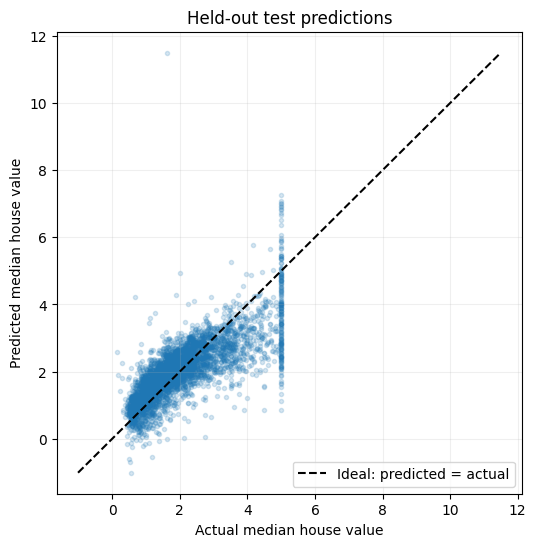

In [51]:
# Inspect predicted versus observed targets on held-out test data.
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_sklearn, alpha=0.18, s=9)
plot_low = min(float(y_test.min()), float(pred_sklearn.min()))
plot_high = max(float(y_test.max()), float(pred_sklearn.max()))
plt.plot([plot_low, plot_high], [plot_low, plot_high],
         "k--", label="Ideal: predicted = actual")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.title("Held-out test predictions")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح محور و خط مرجع</strong><div><ul>
<li><code>plt.scatter(y_test,pred_sklearn)</code> مقدار واقعی روی محور افقی و پیش‌بینی روی محور عمودی قرار دارد.</li>
<li><code>min</code> و <code>max</code> محدودهٔ مشترک را پیدا می‌کنند.</li>
<li><code>plt.plot([low,high],[low,high],"k--")</code> خط قطری ایده‌آل را می‌کشد؛ <code>k--</code> یعنی خط‌چین مشکی.</li>
<li>برای هر نقطه، فاصلهٔ عمودی تا خط قطری با <code>ŷ−y</code> متناظر است؛ خودِ خط قطری <strong>برازش دوم</strong> یا نتیجهٔ آموزش نیست.</li>
<li><code>alpha=0.18</code> به دیدن تراکم نقاط کمک می‌کند.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۵ | باقی‌مانده‌های آزمون</strong><div><p>تفاوت <code>prediction − actual</code> را برای هر سطر آزمون بسازید و الگوی باقی‌مانده‌ها را در نمودار بررسی کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

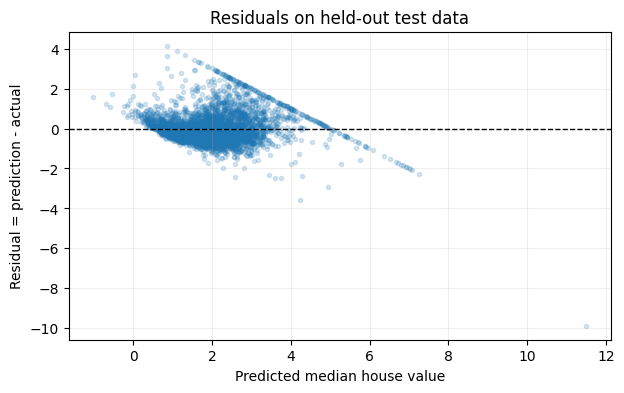

Mean signed test residual: 0.003479297903749609
Mean absolute test residual: 0.5332001304956565


In [52]:
# Plot held-out prediction residuals for qualitative error analysis.
test_residuals = y_test - pred_sklearn  # TODO 15: Compute signed test residuals.
plt.figure(figsize=(7, 4))
plt.scatter(pred_sklearn, test_residuals, alpha=0.18, s=9)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Predicted median house value")
plt.ylabel("Residual = prediction - actual")
plt.title("Residuals on held-out test data")
plt.grid(alpha=0.2)
plt.show()
print("Mean signed test residual:", float(np.mean(test_residuals)))
print("Mean absolute test residual:", float(np.mean(np.abs(test_residuals))))

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح باقی‌مانده و یک اشتباه رایج</strong><div><p><code>test_residuals = pred_sklearn - y_test</code> قرارداد علامت ابتدای درس را نگه می‌دارد. <code>plt.axhline(0)</code> یک خط افقی در صفر رسم می‌کند؛ نقطه‌های بالای آن بیش‌برآورد و زیر آن کم‌برآورد هستند. <code>np.mean(test_residuals)</code> ممکن است به صفر نزدیک شود، <strong>حتی اگر بعضی خطاهای بزرگ وجود داشته باشد</strong>؛ <code>np.mean(np.abs(test_residuals))</code> همان MAE است و خنثی‌شدن علامت‌ها را ندارد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | تمرین کوتاه کلاسی</strong><div><p>در چند سلول بعدی یک محاسبهٔ عددی و یک راستی‌آزمایی استانداردسازی را مستقل انجام می‌دهید. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین مستقل | محاسبه، استانداردسازی و تفسیر</strong><div><p><strong>بخش ۱:</strong> برای خط <code>ŷ=2x+3</code> و <code>x=4</code>، مقدار پیش‌بینی را حساب کنید. اگر <code>y=13</code> باشد، باقی‌مانده و مربع خطا را بنویسید.</p>
<p><strong>بخش ۲:</strong> نخستین مقدار ستون <code>MedInc</code> در Test را با آمار <strong>فقط Train</strong> به Z-score تبدیل کنید و با <code>X_test[0,0]</code> مقایسه کنید.</p>
<p><strong>بخش ۳:</strong> با نگاه به جدول مقایسه، در دو جمله بگویید آیا مدل خطی از پیش‌بین ثابت بهتر است و چرا نباید برای بهبود عدد Test چند بار مدل را دست‌کاری کنیم.</p>
<p>ابتدا حساب‌های ساده را با دست انجام دهید و سپس کد خود را اجرا کنید.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۶ | راستی‌آزمایی Z-score</strong><div><p>مقدار اول ستون اول Test را با میانگین و انحراف معیار همان ستون در Train استاندارد کنید. سپس نتیجه را با آرایهٔ ذخیره‌شده مقایسه کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [ ]:
# Verify the first test row's first-feature Z-score independently.
first_raw_value = X_test_raw[0, 0]
train_first_mean = X_train_raw[:, 0].mean()
train_first_std = X_train_raw[:, 0].std()
first_manual_z = ...  # TODO 16a: Compute the standardized value manually.
print("Manual first-feature Z-score:", first_manual_z)
print("Stored scaled value:", X_test[0, 0])
print("Values agree:", np.isclose(first_manual_z, X_test[0, 0]))

exercise_prediction = ...  # TODO 16b: Predict for x=4 using y_hat=2x+3.
exercise_residual = ...  # TODO 16c: Compute prediction minus actual (actual=13).
print("Exercise prediction / residual / squared error:",
      exercise_prediction, exercise_residual, exercise_residual ** 2)

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح پاسخ و شاخص‌گذاری آرایه‌ها</strong><div><ul>
<li><code>X_test_raw[0,0]</code> سطر اول و ستون اولِ آزمون است.</li>
<li><code>X_train_raw[:,0]</code> یعنی <strong>تمام سطرهای آموزش از ستون اول</strong>؛ دو نقطهٔ <code>:</code> بسیار مهم است.</li>
<li><code>.mean()</code> و <code>.std()</code> آمار ستون اول Train را مستقل محاسبه می‌کنند.</li>
<li><code>np.isclose</code> نزدیکی دو عدد اعشاری را می‌سنجد؛ به دلیل محاسبات اعشاری، مقایسهٔ دقیق با <code>==</code> بهتر نیست.</li>
<li>در مثال اول <code>ŷ=11</code>، مقدار واقعی <code>13</code>، باقی‌مانده <code>−2</code> و مربع خطا <code>4</code> است؛ دقت کنید <strong>مربع خطا</strong> با Half-MSE روی یک نمونه یکی نیست و برای یک نمونه Half-MSE برابر ۲ خواهد بود.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پرسش‌های مرور بخش سوم</strong><div><p>۱) اگر <code>X.shape=(100,8)</code> باشد، شکل <code>w</code> و <code>X@w</code> چیست؟<br/>
۲) آیا مجازیم میانگین ستون‌ها را از Train+Test با هم یاد بگیریم؟ چرا؟<br/>
۳) چرا در ساخت جواب بسته، یک ستون <strong>۱</strong> به <code>X</code> اضافه کردیم؟</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">بخش ۴ | رگرسیون چندجمله‌ای و ساخت ویژگی</strong><div><p>وقتی خط راست برای داده کافی نیست، با ساخت ویژگی‌هایی مثل x²، x³ و x₁x₂ رابطهٔ غیرخطی را مدل می‌کنیم. سپس PolynomialFeatures را روی دادهٔ واقعی‌تر امتحان می‌کنیم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | از خط به منحنی</strong><div><p>ابتدا نشان می‌دهیم چرا می‌توان با ویژگی x² همچنان از رگرسیون خطی در ضرایب برای یک رابطهٔ خمیده استفاده کرد. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

### نمونهٔ خطی‌بودن در ضرایب، نه لزوماً در x

$$
\hat y=w_0+w_1x+w_2x^2
$$

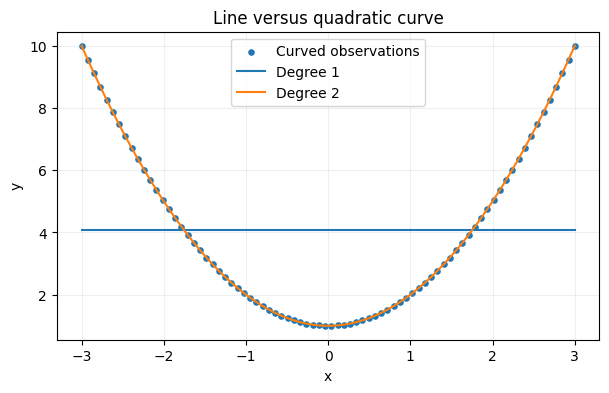

In [53]:
# Compare linear and quadratic fits to curved data.
x_curve = np.linspace(-3, 3, 80)
y_curve = x_curve ** 2 + 1
coef_linear = np.polyfit(x_curve, y_curve, deg=1)
coef_quadratic = np.polyfit(x_curve, y_curve, deg=2)

plt.figure(figsize=(7, 4))
plt.scatter(x_curve, y_curve, s=14, label="Curved observations")
plt.plot(x_curve, np.polyval(coef_linear, x_curve), label="Degree 1")
plt.plot(x_curve, np.polyval(coef_quadratic, x_curve), label="Degree 2")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Line versus quadratic curve")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح سلول مقایسهٔ خط و منحنی</strong><div><ul>
<li><code>x_curve**2 + 1</code> رابطهٔ درجه‌دو و U شکل ایجاد می‌کند.</li>
<li><code>np.polyfit(x_curve,y_curve,deg=1)</code> ضرایب بهترین چندجمله‌ای درجهٔ یک از نظر کمترین مربعات را محاسبه می‌کند؛ <code>deg=2</code> همین کار را برای درجهٔ دو انجام می‌دهد.</li>
<li><code>np.polyval(coef_...,x_curve)</code> از ضرایب برای تولید پیش‌بینی روی همان نقاط استفاده می‌کند.</li>
<li>نمایش روی <strong>همان دادهٔ ساختگی</strong> برای شهود است؛ از آن دربارهٔ تعمیم بهتر به دادهٔ جدید نتیجه نگیرید.</li>
</ul></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | مهندسی ویژگی چندجمله‌ای</strong><div><p>در این بخش ستون‌های x²، x³ و ضرب دو ویژگی را می‌سازیم و تفاوت «درجهٔ مدل» با «نوع حل‌گر» را توضیح می‌دهیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">ریاضیات رگرسیون چندجمله‌ای؛ دقیق اما قابل‌فهم</strong><div><p>«برای یک ورودی x، مدل درجهٔ دو این است: <code>ŷ = b + w₁x + w₂x²</code>. ما لازم نیست منحنی را با الگوریتم تازه‌ای آموزش بدهیم؛ فقط به مدل خطی می‌گوییم دو ویژگی جدید داریم: ستون اول x و ستون دوم x². اگر درجهٔ سه بخواهیم، x³ هم اضافه می‌شود. بنابراین فرم کلی در ویژگی‌های تبدیل‌شده همچنان ضرب ماتریسی است.»</p><p>«اگر فقط یک x داریم، به‌ازای درجهٔ d و با بایاس جداگانه d ستون خواهیم داشت: x، x²، ...، xᵈ. هرچه درجه بالاتر باشد، شکل‌های انعطاف‌پذیرتری می‌توانیم بسازیم؛ اما انعطاف زیاد به‌تنهایی مساوی کیفیت بهتر روی دادهٔ جدید نیست.»</p></div></div>

### فرمول رگرسیون چندجمله‌ای و خطی‌ماندن نسبت به ضرایب

$$
\hat y=b+w_1x+w_2x^2+\cdots+w_dx^d,
\qquad
\phi(x)=\begin{bmatrix}x & x^2 & \cdots & x^d\end{bmatrix}^{\mathsf T},
\qquad
\hat y=b+\mathbf w^{\mathsf T}\phi(x).
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">مثال دستی | برای x=2 چه ویژگی‌هایی می‌سازیم؟</strong><div><p>اگر ویژگی خام x=2 و درجهٔ موردنظر ۳ باشد، ویژگی‌های جدید [۲،۴،۸] می‌شوند؛ یعنی x، x²، x³. اگر <code>b=1</code> و وزن‌ها <code>[2,−1,0.5]</code> باشند، خروجی برابر <code>1 + 2×2 − 1×4 + 0.5×8 = 5</code> است.</p><p><strong>پرسش:</strong> «چرا این مدل با وجود x² و x³ هنوز در خانوادهٔ مدل‌های خطی آموزش دیده می‌شود؟» چون هیچ ضریبی مربع نشده یا در ضریب دیگری ضرب نمی‌شود؛ رابطه نسبت به <strong>ضرایب</strong> خطی است، هرچند نسبت به x غیرخطی است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۷ | ساخت دستی ویژگی‌های چندجمله‌ای</strong><div><p>برای ورودی <code>x_value</code> یک بردار شامل توان‌های ۱، ۲ و ۳ بسازید. سپس ضرب داخلی با وزن‌ها را بررسی کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [54]:
# Build degree-three features manually for a single observation.
x_value = 2.0
features_manual = np.array([x_value, x_value**2, x_value**3]) # TODO 17: Build x, x^2, and x^3 features.
weights_example = np.array([2.0, -1.0, 0.5])
bias_example = 1.0
print("Manual features:", features_manual)
print("Manual prediction:", bias_example + features_manual @ weights_example)

Manual features: [2. 4. 8.]
Manual prediction: 5.0


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح خط‌به‌خط ویژگی‌های دستی</strong><div><p><code>x_value</code> همان ورودی خام است؛ توان <code>**2</code> مربع و <code>**3</code> مکعب می‌سازد. <code>features_manual</code> بردار سه‌عضوی است و <code>weights_example</code> سه وزن متناظر دارد. علامت <code>@</code> حاصل‌ضرب داخلی این دو بردار را حساب می‌کند. در پایان <code>bias_example</code> اضافه می‌شود. این کد <strong>آموزش</strong> نیست؛ پیش‌بینی با ضرایب از پیش انتخاب‌شده است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0ea5e9;border-radius:8px;background:rgba(14,165,233,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پیش از شروع | PolynomialFeatures در Scikit-Learn</strong><div><p>به‌جای ساختن دستی توان‌ها و جملات تعاملی، از خودتان PolynomialFeatures برای تولید منظم همهٔ ستون‌ها استفاده می‌کنیم. <strong>در چند سلول بعدی</strong> ابتدا مفهوم را توضیح می‌دهیم، سپس سراغ فرمول/کد و تفسیر خروجی می‌رویم.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">درجهٔ ۲ برای دو ورودی یعنی چه؟</strong><div><p>«اگر دو ویژگی اولیه x₁ و x₂ باشند، مدل درجهٔ دو تنها x₁² و x₂² را اضافه نمی‌کند؛ جملهٔ تعاملیِ <strong>x₁x₂</strong> هم ایجاد می‌شود. دلیلش این است که می‌خواهیم همهٔ تک‌جمله‌ای‌هایی را داشته باشیم که مجموع توان‌هایشان حداکثر ۲ باشد. در این صورت ستون‌های جدید عبارت‌اند از x₁، x₂، x₁²، x₁x₂، x₂².»</p><p>«برای <code>PolynomialFeatures(degree=2, include_bias=False)</code> ستون ثابتِ ۱ ساخته نمی‌شود، چون <code>LinearRegression(fit_intercept=True)</code> خودش بایاس را جداگانه یاد می‌گیرد. اگر هر دو را وارد کنیم ممکن است ستون ثابت تکراری بسازیم؛ هرچند حل‌گر می‌تواند با دادهٔ وابسته هم کار کند.»</p></div></div>

### تمام جملات درجهٔ دو برای دو ویژگی

$$
\phi(x_1,x_2)=\begin{bmatrix}
x_1 & x_2 & x_1^2 & x_1x_2 & x_2^2
\end{bmatrix}^{\mathsf T}.
$$

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۸ | PolynomialFeatures</strong><div><p>تبدیل‌گر درجهٔ دو را برای دو ویژگی بسازید (بدون ستون ثابت) و خروجی آن را روی دادهٔ کوچک محاسبه کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [55]:
# Inspect feature expansion for a small two-feature dataset.
two_features = np.array([[2.0, 3.0], [1.0, -2.0]])
polynomial_builder = PolynomialFeatures(degree=2, include_bias=False) # TODO 18a: Create a degree-2 transformer without a bias column.
two_features_expanded = polynomial_builder.fit_transform(two_features)  # TODO 18b: Fit and transform the toy feature matrix.
print("Raw shape:", two_features.shape)
print("Expanded shape:", two_features_expanded.shape)
print("Feature names:", polynomial_builder.get_feature_names_out(["x1", "x2"]))
print("Expanded rows:\n", two_features_expanded)

Raw shape: (2, 2)
Expanded shape: (2, 5)
Feature names: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
Expanded rows:
 [[ 2.  3.  4.  6.  9.]
 [ 1. -2.  1. -2.  4.]]


In [58]:
# Inspect feature expansion for a small two-feature datase as scratch
two_features = np.array([[2.0, 3.0], [1.0, -2.0]])

x1 = two_features[: , 0]
x2 = two_features[: , 1]\

two_features_expanded = np.column_stack([
    x1, 
    x2, 
    x1 ** 2 , 
    x1 * x2 , 
    x2 ** 2
])

feature_names = ["x1" ,"x2" , "x1^2" , "x1 x2" , "x2 ^ 2" ]

# polynomial_builder = ...  # TODO 18a: Create a degree-2 transformer without a bias column.
# two_features_expanded = ...  # TODO 18b: Fit and transform the toy feature matrix.
print("Raw shape:", two_features.shape)
print("Expanded shape:", two_features_expanded.shape)
print("Feature names:", feature_names)
print("Expanded rows:\n", two_features_expanded)

Raw shape: (2, 2)
Expanded shape: (2, 5)
Feature names: ['x1', 'x2', 'x1^2', 'x1 x2', 'x2 ^ 2']
Expanded rows:
 [[ 2.  3.  4.  6.  9.]
 [ 1. -2.  1. -2.  4.]]


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمام سطرهای PolynomialFeatures</strong><div><p><code>two_features</code> دو ردیف داده با دو ستون ورودی است. <code>PolynomialFeatures</code> ابزاری برای <strong>تبدیل X</strong> است، نه یک مدلِ پیش‌بینی. با <code>fit_transform</code> روی دادهٔ نمونه مشخصات تبدیل را تعیین کرده و آرایهٔ گسترش‌یافته را می‌سازیم. شکل خام (۲،۲) است، اما شکل جدید (۲،۵) خواهد بود. <code>get_feature_names_out</code> اسم‌های x1، x2، x1²، x1 x2 و x2² را چاپ می‌کند.</p><p>برای ردیف [۲،۳] باید [۲،۳،۴،۶،۹] ایجاد شود. <strong> قبل از اجرا حدس بزنید عدد ۶ از کجا آمده است.</strong> پاسخ: جملهٔ تعاملی ۲×۳.</p></div></div>

In [59]:
# Load a multifeature regression dataset included with this package.
poly_df = pd.read_csv(DATA_DIR / "polynomial_dataset.csv")
print("Shape:", poly_df.shape)
print("Columns:", poly_df.columns.tolist())
print("Missing values:", int(poly_df.isna().sum().sum()))
display(poly_df.head())
poly_X_raw = poly_df.drop(columns="y")
poly_y = poly_df["y"]
poly_X_train, poly_X_test, poly_y_train, poly_y_test = train_test_split(
    poly_X_raw, poly_y, test_size=0.25, random_state=SEED
)
print("Train/Test:", poly_X_train.shape, poly_X_test.shape)

Shape: (500, 5)
Columns: ['x1', 'x2', 'x3', 'x4', 'y']
Missing values: 0


,x1,x2,x3,x4,y
0,0.496714,0.926178,1.399355,0.609373,1.561301
1,-0.138264,1.909417,0.924634,-0.303433,-5.185185
2,0.647689,-1.398568,0.059630,0.061334,-2.034650
3,1.523030,0.562969,-0.646937,0.912468,2.200069
4,-0.234153,-0.650643,0.698223,-0.208566,-1.777802


Train/Test: (375, 4) (125, 4)


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین ۱۹ | مقایسهٔ رگرسیون خطی و چندجمله‌ای</strong><div><p>در مسئلهٔ چندویژگی، تبدیل درجهٔ دو را فقط با Train برازش کنید؛ دادهٔ Test را با همان تبدیل‌گر نگاشت کنید، سپس مدل درجهٔ دو را fit کنید.</p><p><strong>کار شما:</strong> همهٔ <code>...</code>های این سلول را تکمیل کنید و بعد سلول را اجرا کنید.</p></div></div>

In [60]:
# Compare raw linear regression with degree-two polynomial regression.
raw_model = LinearRegression()
raw_model.fit(poly_X_train, poly_y_train)
raw_train_pred = raw_model.predict(poly_X_train)
raw_test_pred = raw_model.predict(poly_X_test)

poly2_transformer = PolynomialFeatures(degree=2, include_bias=False)
poly2_train = poly2_transformer.fit_transform(poly_X_train)  # TODO 19a: Fit-transform training features.
poly2_test = poly2_transformer.fit_transform(poly_X_test)   # TODO 19b: Transform test features without fitting again.
poly2_model = LinearRegression()
poly2_model.fit(poly2_train, poly_y_train)  # TODO 19c: Fit the polynomial linear model on transformed training data.
poly2_train_pred = poly2_model.predict(poly2_train)
poly2_test_pred = poly2_model.predict(poly2_test)

print("Raw features:", poly_X_train.shape[1])
print("Degree-two features:", poly2_train.shape[1])
print("Generated feature names:", poly2_transformer.get_feature_names_out(poly_X_train.columns))
display(pd.DataFrame([
    {"Model": "Raw linear", "Train RMSE": np.sqrt(mean_squared_error(poly_y_train, raw_train_pred)),
     "Test RMSE": np.sqrt(mean_squared_error(poly_y_test, raw_test_pred)),
     "Test R2": r2_score(poly_y_test, raw_test_pred)},
    {"Model": "Polynomial degree 2", "Train RMSE": np.sqrt(mean_squared_error(poly_y_train, poly2_train_pred)),
     "Test RMSE": np.sqrt(mean_squared_error(poly_y_test, poly2_test_pred)),
     "Test R2": r2_score(poly_y_test, poly2_test_pred)}
]).round(4))

Raw features: 4
Degree-two features: 14
Generated feature names: ['x1' 'x2' 'x3' 'x4' 'x1^2' 'x1 x2' 'x1 x3' 'x1 x4' 'x2^2' 'x2 x3' 'x2 x4'
 'x3^2' 'x3 x4' 'x4^2']


,Model,Train RMSE,Test RMSE,Test R2
0,Raw linear,2.5575,2.858,0.5429
1,Polynomial degree 2,1.7065,1.857,0.8070


<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">شرح کد مدل چندجمله‌ای</strong><div><p><strong>بلوک اول:</strong> مدل <code>raw_model</code> فقط چهار ویژگی اصلی را می‌بیند؛ <code>fit</code> ضرایب را از Train می‌آموزد. <code>predict</code> روی Train و Test اجرا می‌شود تا هم برازش و هم ارزیابی مستقل را ببینیم.</p><p><strong>بلوک دوم:</strong> <code>poly2_transformer</code> تمام جملات تا درجهٔ ۲ را می‌سازد. <code>fit_transform(poly_X_train)</code> شکل جدید آموزش را تولید می‌کند و <code>transform(poly_X_test)</code> دقیقاً همان ترتیب ستون‌ها را برای آزمون حفظ می‌کند. از چهار ویژگی اولیه باید <strong>۱۴ ویژگی</strong> حاصل شود: ۴ ویژگی درجهٔ اول و ۱۰ جملهٔ درجهٔ دوم (چهار مربع و شش ضرب دوتایی).</p><p><strong>بلوک سوم:</strong> <code>poly2_model</code> همچنان یک <code>LinearRegression</code> معمولی است؛ فقط ستون‌های بیشتری دریافت می‌کند. جدول پایانی RMSE و R² را روی Test و RMSE را روی Train مقایسه می‌کند. کمتر شدن خطای آموزش با افزودن ویژگی‌ها طبیعی است، اما آنچه برای تعمیم مهم است عملکرد روی دادهٔ ندیده است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #d97706;border-radius:8px;background:rgba(245,158,11,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">چرا درجهٔ بالاتر الزاماً بهتر نیست؟</strong><div><p>«هر بار که درجهٔ چندجمله‌ای را زیاد می‌کنیم، ستون‌های بیشتری می‌سازیم. از دید آموزش، مدل پرانعطاف‌تر می‌شود و می‌تواند حتی تغییرات تصادفی داده را دنبال کند. اما هدف ما تقلید تک‌تک نقطه‌های Train نیست؛ باید روی دادهٔ جدید هم خوب پیش‌بینی کنیم.»</p><p>«برای اینکه صرفاً نتیجهٔ Train را معیار نکنیم، در مثال بعد یک مجموعهٔ Test جدا داریم. برای هر درجه تعداد ستون‌ها و RMSE دو بخش را نشان می‌دهیم. اگر خطای Train خیلی پایین باشد اما Test بد شود، یک نشانهٔ بیش‌برازش است؛ بررسی کامل Overfitting و انتخاب درجه با Validation موضوع مرحلهٔ بعدی یادگیری است.»</p></div></div>

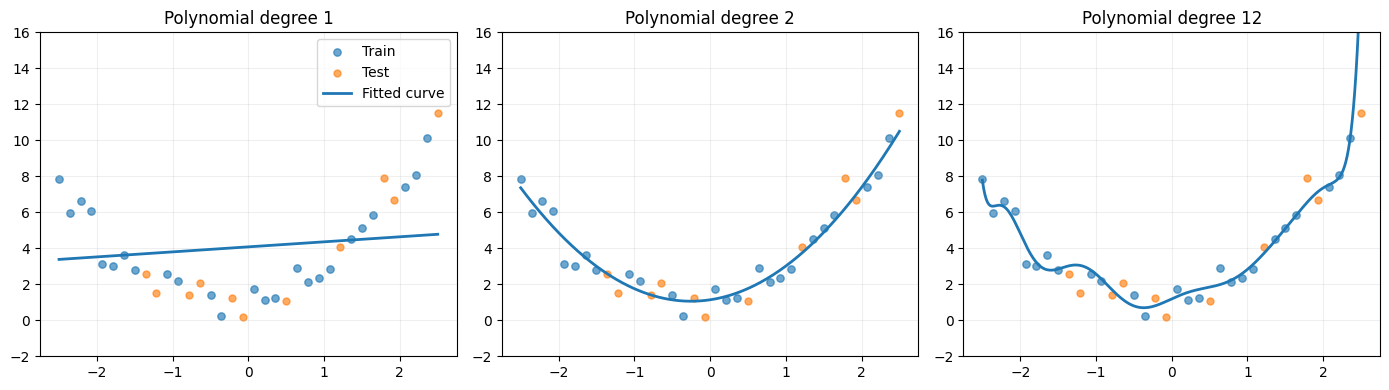

,Degree,Train RMSE,Test RMSE
0,1,2.4914,3.1555
1,2,0.6075,0.7748
2,12,0.4344,2.6580


In [61]:
# Visualize polynomial degree and generalization on a small noisy problem.
curve_rng = np.random.default_rng(SEED)
curve_x = np.linspace(-2.5, 2.5, 36)
curve_y = 1.0 + 0.6 * curve_x + 1.3 * curve_x**2 + curve_rng.normal(0, 0.8, size=curve_x.size)
curve_x_train, curve_x_test, curve_y_train, curve_y_test = train_test_split(
    curve_x.reshape(-1, 1), curve_y, test_size=0.3, random_state=SEED
)
plot_x = np.linspace(-2.5, 2.5, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
results_degree = []
for ax, degree in zip(axes, [1, 2, 12]):
    mapper = PolynomialFeatures(degree=degree, include_bias=False)
    mapped_train = mapper.fit_transform(curve_x_train)
    mapped_test = mapper.transform(curve_x_test)
    fitted_model = LinearRegression().fit(mapped_train, curve_y_train)
    train_pred = fitted_model.predict(mapped_train)
    test_pred = fitted_model.predict(mapped_test)
    results_degree.append({"Degree": degree, "Train RMSE": np.sqrt(mean_squared_error(curve_y_train, train_pred)),
                           "Test RMSE": np.sqrt(mean_squared_error(curve_y_test, test_pred))})
    ax.scatter(curve_x_train[:, 0], curve_y_train, s=28, alpha=0.65, label="Train")
    ax.scatter(curve_x_test[:, 0], curve_y_test, s=25, alpha=0.65, label="Test")
    ax.plot(plot_x[:, 0], fitted_model.predict(mapper.transform(plot_x)), linewidth=2, label="Fitted curve")
    ax.set_title(f"Polynomial degree {degree}")
    ax.set_ylim(-2, 16)
    ax.grid(alpha=0.2)
axes[0].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(results_degree).round(4))

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #0891b2;border-radius:8px;background:rgba(8,145,178,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">توضیح تمام بلوک‌های نمودار درجه‌ها</strong><div><p><strong>تولید داده:</strong> <code>curve_x</code> ۳۶ مقدار را تعیین می‌کند و <code>curve_y</code> از یک رابطهٔ درجهٔ دو همراه نویز ساخته می‌شود. <code>default_rng(SEED)</code> امکان اجرای تکرارپذیر را فراهم می‌کند. <code>train_test_split</code> ردیف‌های Train و Test را جدا می‌کند.</p><p><strong>سه بار آموزش:</strong> حلقهٔ <code>for</code> برای درجه‌های ۱، ۲ و ۱۲ یک تبدیل و یک مدل مستقل می‌سازد. <code>fit_transform</code> فقط با Train انجام می‌شود؛ <code>transform</code> برای Test و نقاط صافِ رسم نمودار استفاده می‌شود. <code>LinearRegression().fit(...)</code> ضرایب همان درجه را آموزش می‌دهد.</p><p><strong>خواندن خروجی:</strong> دو نوع نقطه نشانهٔ Train و Test هستند؛ منحنی خط یادگرفته‌شده است. جدول، خطای Train و Test را جدا گزارش می‌کند. با درجهٔ زیاد ممکن است مدل روی نقاط آموزش پیچ‌وتاب بخورد و روی Test بدتر شود؛ در چنین وضعی افزایش پیچیدگی کمکی به تعمیم نمی‌کند.</p><p><strong>نکتهٔ علمی:</strong> چون درجهٔ ۱۲ با ویژگی‌های بزرگ محاسبات عددی حساس‌تری دارد، رفتار دقیق منحنی در بیرون بازهٔ داده می‌تواند شدید باشد؛ از نمودار برای فهم کلی پیچیدگی استفاده کنید، نه نتیجهٔ قطعی دربارهٔ هر دیتاست.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پرسش‌های مرور نهایی هفتهٔ ۱۱</strong><div><p>۱) در یک جمله تفاوت <code>fit</code> و <code>predict</code> را بگو.<br/>
۲) چرا استانداردسازی را باید بعد از جداسازی Train/Test یاد بگیریم؟<br/>
۳) اگر <code>MAE=0.3</code> در دادهٔ مسکن باشد، حدوداً چند دلار خطای مطلق متوسط داریم؟<br/>
۴) <code>R²=0.7</code> یعنی ۷۰٪ پیش‌بینی‌های ما دقیق‌اند؟<br/>
۵) یک تفاوت Gradient Descent و شبه‌معکوس را توضیح بده.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">پرسش‌های مفهومی برای مرور</strong><div><p>توضیح دهید چرا بهترین خط OLS لزوماً خطای صفر ندارد، چرا بزرگی ضرایب بدون توجه به مقیاس نشانهٔ اهمیت نیست، چرا <code>R²</code> روی Test ممکن است منفی شود و چرا عملکرد مدل روی Test با عملکرد روی Train متفاوت است.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">تمرین تکمیلی پایان هفته</strong><div><p><strong>بخش الف ـ دستی :</strong> سه نقطهٔ <code>(1,2), (2,3), (3,5)</code> را بردار. در <code>w=1,b=1</code> مقدار J و دو گرادیان را حساب کن و با <code>α=0.1</code> یک گام وزن‌ها را تغییر بده. <strong>تمام مراحل عددی</strong> را بنویس.</p>
<p><strong>بخش ب ـ کد :</strong> روی دادهٔ هشت‌نفرهٔ بخش اول، <code>fit_simple_gd</code> را با سه نرخ یادگیریِ پایدار اجرا کن، هزینهٔ اول و آخر و ضرایب نهایی را در جدول بنویس و توضیح بده چرا یک نرخ برای تعداد گام ثابت بهتر جلو رفته است.</p>
<p><strong>بخش ج ـ تفسیر :</strong> روی دادهٔ مسکن <code>MAE</code> و <code>R²</code> را برای مدل ثابت و مدل خطی مقایسه کن. در سه تا پنج خط توضیح بده چرا نباید Test را برای انتخابِ بهترین نرخ یادگیری بارها امتحان کرد. تحویل باید علاوه بر کد، <strong>توضیح کوتاه خود </strong> داشته باشد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #2563eb;border-radius:8px;background:rgba(37,99,235,.09);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">منابع و قراردادهای علمی همین نوت‌بوک</strong><div><p>اصطلاحات و API: مستندات NumPy (<code>numpy.ndarray</code>, <code>numpy.linalg.pinv</code>)، Pandas (<code>read_csv</code>, <code>DataFrame</code>)، Scikit-Learn (<code>LinearRegression</code>, <code>DummyRegressor</code>, <code>train_test_split</code>, <code>mean_absolute_error</code>, <code>mean_squared_error</code>, <code>r2_score</code>، <code>PolynomialFeatures</code>). فرمول‌های مشتق و کمترین مربعات برای تابع هزینهٔ <code>J=(1/2m)Σ(ŷ−y)²</code> نوشته شده‌اند. واحد هدف دیتاست <strong>۱۰۰ هزار دلار</strong> است. دیتا با فایل همراه تحویل می‌شود و برای اجرا به دریافت آنلاین نیاز ندارد.</p></div></div>

<div dir="rtl" lang="fa" style="display:block;box-sizing:border-box;width:calc(100% - 20px);max-width:calc(100% - 20px);min-width:0;margin:10px 0 10px 10px;padding:12px 16px;border:1px solid rgba(148,163,184,.35);border-right:5px solid #16a34a;border-radius:8px;background:rgba(34,197,94,.10);direction:rtl;text-align:right;white-space:normal;overflow-wrap:anywhere;overflow:hidden;line-height:1.9;color:inherit;"><strong style="display:block;margin-bottom:4px;">گزارش کوتاهِ پایان فعالیت</strong><div><p>پس از کامل کردن تمرین‌ها، در چند جمله بنویسید: چرا <code>Gradient Descent</code> و <code>np.linalg.pinv</code> ممکن است پیش‌بینی‌های نزدیک تولید کنند؟ معیارهای <code>MAE</code> و <code>RMSE</code> در برابر یک خطای خیلی بزرگ چه تفاوتی دارند؟ و چرا اضافه‌کردن ویژگی‌های چندجمله‌ای لزوماً روی دادهٔ ندیده نتیجه را بهتر نمی‌کند؟</p></div></div>